# Исследование территории: муниципальный округ Пороховые (Санкт-Петербург)

Учебное исследование городской территории средствами **BlocksNet 1.0.0a9**.
Ноутбук повторяет все показатели из официального примера `examples/pipeline.ipynb`
(нарезка кварталов → land use → матрица доступности → здания → школы →
обеспеченность → плотность → морфотипы → площадная доступность), но для конкретной территории.

| Параметр | Значение |
|---|---|
| Территория | муниципальный округ Пороховые, Красногвардейский район Санкт-Петербурга |
| Граница | OpenStreetMap, relation `R1185384` |
| Способ передвижения | **автомобиль (drive)** по готовому графу BlocksNet Data |
| Время в пути | **минуты** (`time_min`) |
| Услуга | только **школы** (как в `pipeline.ipynb`) |
| Данные | `examples/data/porokhovye/raw/` и `examples/data/porokhovye/processed/` |
| Итоговый дашборд | отдельный этап: `dashboard.html`, строго меньше 20 МБ |

> **Главное ограничение, которое нужно держать в голове.**
> Школьники обычно **ходят в школу пешком**, а здесь доступность считается **на автомобиле**.
> За 15 минут на машине доступна почти вся территория округа, поэтому формальная
> обеспеченность школами может быть **завышена**. Это учебная модельная оценка,
> а не нормативный вывод о доступности школьного образования.

## 1. Как устроен ноутбук

1. **Запускайте ячейки сверху вниз** кнопкой ▶ или `Shift+Enter` в VS Code.
2. Первый запуск скачивает данные из OpenStreetMap и готовый граф, затем считает матрицу времени.
   Это может занять **20–60 минут** (в основном из-за Overpass API и матрицы).
3. Все слои сохраняются в файлы. При повторном запуске готовые файлы **читаются с диска**,
   а не скачиваются заново. Повторный запуск обычно занимает несколько минут.
4. После раздела **«⛔ ОСТАНОВКА»** ноутбук намеренно останавливается:
   нужно согласовать список метрик и услуг, прежде чем считать показатели.
5. Все длины — в метрах, площади — в м² и км², время — в **минутах**,
   население — в человека, вместимость школ — в местах.
6. В таблицах и подписях явно разделены:
   * **исходные данные** — то, что пришло из OSM или готового графа;
   * **модельная оценка** — то, что восстановлено или рассчитано BlocksNet/IduEdu.

7. Если непонятно, что означает показатель — смотрите раздел **12.0**: там словарь
   всех метрик, единицы измерения и подсказки, как читать числа.

### Структура папок после запуска

```
examples/
├── porokhovye_research.ipynb          ← этот ноутбук
├── build_porokhovye_dashboard.py      ← сборка dashboard.html
├── dashboard.html                     ← результат, открыть в браузере
└── data/porokhovye/
    ├── raw/                           ← исходные данные (GeoJSON, pickle)
    │   ├── boundary.geojson
    │   ├── roads.geojson
    │   ├── railways.geojson
    │   ├── water.geojson
    │   ├── functional_zones.geojson
    │   ├── buildings.geojson
    │   ├── school.geojson
    │   ├── parks_green.geojson
    │   ├── parkings.geojson
    │   └── graph_drive.pickle
    └── processed/                     ← результаты и промежуточные слои
        ├── blocks_cut.geojson         ← нарезка без объединения
        ├── blocks.geojson             ← итоговые кварталы
        ├── blocks_land_use.geojson
        ├── graph_drive_clipped.pickle
        ├── graph_edges.geojson
        ├── accessibility_matrix.csv
        ├── blocks_buildings.geojson
        ├── blocks_schools.geojson
        ├── blocks_provision.geojson
        ├── blocks_density.geojson
        ├── blocks_spacematrix.geojson
        ├── blocks_strelka.geojson
        ├── blocks_area_accessibility.geojson
        ├── blocks_results.geojson
        ├── provision_links.csv
        ├── summary.json
        └── summary.csv
```

## 2. План работы

| № | Задача | Результат |
|---|---|---|
| 1 | Проверить окружение, версии библиотек и папки | Ноутбук печатает версии, путь к данным |
| 2 | Загрузить границу округа по OSM `R1185384` | `raw/boundary.geojson`, площадь территории |
| 3 | Загрузить дороги, железные дороги и воду | `raw/roads.geojson`, `raw/railways.geojson`, `raw/water.geojson` |
| 4 | Загрузить функциональные зоны, парки, парковки, здания и школы | `raw/functional_zones.geojson`, `raw/parks_green.geojson`, `raw/parkings.geojson`, `raw/buildings.geojson`, `raw/school.geojson` |
| 5 | Нарезать кварталы, объединить «пылинки» и назначить land use | `processed/blocks.geojson`, `processed/blocks_land_use.geojson` |
| 6 | Проверить качество кварталов и **остановиться** | Таблица качества, согласование метрик |
| 7 | Скачать готовый автомобильный граф и обрезать по территории | `raw/graph_drive.pickle`, `processed/graph_drive_clipped.pickle` |
| 8 | Рассчитать матрицу времени между кварталами | `processed/accessibility_matrix.csv` |
| 9 | Подготовить здания и население | `processed/blocks_buildings.geojson` |
| 10 | Подготовить школы и вместимость | `processed/blocks_schools.geojson` |
| 11 | Рассчитать обеспеченность школами | `processed/blocks_provision.geojson`, `provision_links.csv` |
| 12 | Рассчитать плотность и морфотипы | `blocks_density/spacematrix/strelka.geojson` |
| 13 | Рассчитать площадную доступность | `blocks_area_accessibility.geojson` |
| 14 | Собрать итоговый слой и сводку | `blocks_results.geojson`, `summary.json`, `summary.csv` |
| 15 | Проверить результаты по чек-листу | `[OK]` / `[!]`, карты и графики |
| 16 | Сформулировать краткие выводы и ограничения | Текст в конце ноутбука |
| 17 | Собрать один HTML-дашборд (< 20 МБ) | `examples/build_porokhovye_dashboard.py` → `examples/dashboard.html` |

**Что считается на этом этапе:** кварталы, land use, матрица времени, население,
вместимость школ, конкурентная обеспеченность, плотность (FSI/GSI/MXI/L/OSR),
морфотипы Spacematrix и Strelka, площадная доступность.

**Что не входит:** детские сады, поликлиники и другие услуги; пешеходный граф;
официальные данные Росстата и ПЗЗ; расчёт сценариев новой застройки.

> **Отклонения от `pipeline.ipynb` (по результатам проверки территории).**
> Пример `pipeline.ipynb` **не фильтрует и не объединяет** мелкие кварталы — он оставляет все.
> В этом ноутбуке сознательно добавлены четыре правки, которых в примере нет:
> (1) объединение «кварталов-пылинок» меньше 500 м² с соседями;
> (2) загрузка парков и зелёных зон (`leisure=park/garden`) как recreation;
> (3) загрузка парковок (`amenity=parking`) и правила `railway`, `depot` → transport;
> (4) отбрасывание узких и мелких газонов, чтобы трава вдоль дорог и путей
> не перекрывала основное назначение квартала.
> Все четыре правки помечены в разделе 7.2.

**Словарь показателей.** Что означает каждый показатель, в каких единицах он измеряется
и что он говорит о территории — раздел **12.0**. Там же таблица соответствия
«показатель из `pipeline.ipynb` → где считается → как показан».

## 3. Данные: источники, единицы измерения, ограничения

| Слой | Источник | Единицы | Тип данных | Ограничение |
|---|---|---|---|---|
| Граница округа | OpenStreetMap / Nominatim, relation `R1185384` | полигон; м², км² | исходные | Административная граница OSM может отличаться от официальной |
| Дороги | OpenStreetMap через Overpass API (`osmnx`) | линии; м | исходные | Полнота зависит от OSM; локальные проезды могут отсутствовать |
| Железные дороги | OpenStreetMap через Overpass API | линии; м | исходные | Барьеры могут быть неполными |
| Вода | OpenStreetMap через Overpass API | полигоны и линии; м² | исходные | Береговые линии упрощены в OSM |
| Функциональные зоны | OpenStreetMap, тег `landuse` | полигоны; м² | исходные | Это **не** официальные ПЗЗ и не документы зонирования |
| Здания: контур, тип, этажность | OpenStreetMap, тег `building`, `building:levels` | м², этажи | исходные | Этажность заполнена не у всех зданий |
| Здания: площади и население | расчёт `impute_buildings` | м², чел. | **модельная оценка** | Если этажность не указана — 1 этаж; жилая площадь = 0.9 × площадь этажей; 30 м²/чел. |
| Школы: расположение | OpenStreetMap, тег `amenity=school` | точки/полигоны | исходные | Школы могли быть закрыты, перепрофилированы или не отмечены |
| Школы: вместимость | расчёт `impute_services` | места | **модельная оценка** | При отсутствии данных ставится минимальная вместимость из конфигурации BlocksNet — **250 мест** |
| Граф доступности | BlocksNet Data, release `v0.0.1`, файл `graph_drive.pickle` | минуты | готовый граф | Автомобиль, без пробок; скорости по модели IduEdu |
| Матрица времени | расчёт IduEdu по графу | минуты | **модельная оценка** | Время между центрами кварталов; включает подход к узлу сети |
| Показатели BlocksNet | расчёт по слоям | безразмерные, минуты, чел. | **модельная оценка** | Зависят от качества исходных данных и допущений |

### Как фактически скачивались данные

При первом запуске основной сервер Overpass (`overpass-api.de`) вернул ошибку **502 Bad Gateway**.
Поэтому в ноутбук добавлена отдельная ячейка с зеркалом
`https://maps.mail.ru/osm/tools/overpass/api` и отключённым ограничением частоты
(`ox.settings.overpass_rate_limit = False`, потому что зеркало не поддерживает эндпоинт `/status`).
Источник данных при этом не меняется — это тот же **OpenStreetMap**;
зеркало влияет только на сервер, который обрабатывает запрос.

### Ограничения, которые важно проговорить в выводах

* **Автомобиль вместо пешехода.** Норматив 15 минут в BlocksNet — это 15 минут по выбранному графу.
  Для школ корректнее пешеходная доступность. На автомобиле 15 минут покрывают почти весь округ,
  поэтому обеспеченность может быть **завышена**.
* **Вместимость школ — модель.** В OSM почти никогда нет числа мест; используется 250 мест на школу.
* **Население — модель.** Оно восстановлено из жилой площади зданий, а не взято из Росстата.
* **Этажность — частично модель.** Пропуски заполнены 1 этажом, что может занижать население
  и плотность в районах старой застройки.
* **Функциональные зоны — OSM `landuse` + парки и парковки.** Это не официальные ПЗЗ.
  Парки (`leisure=park/garden`) и парковки (`amenity=parking`) добавлены отдельными слоями
  по результатам проверки территории.
* **Граф без пробок и без общественного транспорта.** Это не прогноз транспортной доступности.

## 4. Основные запросы к ИИ

| Запрос | Что сделано в ноутбуке |
|---|---|
| «Спланируй учебное исследование Пороховых по примеру `pipeline.ipynb`» | Составлен план из 17 задач, структура разделов и файлов |
| «Используй установленный BlocksNet 1.0.0a9» | Проверка версии и импорты под API 1.0.0a9 |
| «Выбери готовый граф, не строй интермодальный» | Скачивается `graph_drive.pickle` из BlocksNet Data `v0.0.1`, режим — автомобиль |
| «Укажи источник графа и способ передвижения, время в минутах» | Печать источника, режима и веса `time_min`; все времена в минутах |
| «Сохраняй данные и переиспользуй готовые файлы» | GeoJSON в `raw/` и `processed/`, матрица в CSV, граф в pickle, флаги `FORCE_*` |
| «Сделай остановку после подготовки кварталов» | Ячейка «⛔ ОСТАНОВКА» и защитный барьер перед расчётами |
| «Отдели исходные данные от модельных оценок» | Таблица источников, суффиксы `_osm`, явные подписи «модель» |
| «Добавь разделы: план, запросы к ИИ, выводы, повторный запуск» | Разделы 2, 4, 15, 17 |
| «Учти ограничение: школьники ходят пешком» | Предупреждение в разделах 3, 11, 15, 16 |
| «Дашборд должен быть меньше 20 МБ» | Бюджет размера и проверка лимита описаны в разделе 18 |
| «Сделай отдельный скрипт, который соберёт `dashboard.html` из готовых файлов» | `examples/build_porokhovye_dashboard.py`: читает GeoJSON/CSV, не скачивает и не пересчитывает |
| «Я живу здесь: проверь парки, парковки, железную дорогу и мелкие кварталы» | Добавлены парки и парковки, `railway`/`depot` → transport, объединение «пылинок», фильтр газонов |
| «Почему мелкие кварталы не объединяются, как в `pipeline.ipynb`?» | В примере они не фильтруются; объединение < 500 м² добавлено как явное отклонение |

### 4.1. Исправления, сделанные с помощью второго ИИ-ассистента (Claude)

Бесплатный лимит OpenCode заканчивался во время работы, поэтому часть ошибок
разбиралась и исправлялась с помощью ассистента Claude (Claude Code). Все исправления проверены запуском.

| Проблема | Причина | Исправление |
|---|---|---|
| Загрузка OSM падала с `502 Bad Gateway` | Основной сервер `overpass-api.de` перегружен | Ячейка перед разделом 6: зеркало `maps.mail.ru`, `overpass_rate_limit = False` (зеркало не поддерживает `/status`, из-за этого загрузка зависала) |
| Ядро аварийно завершалось на расчёте матрицы (раздел 9) | IduEdu использует номера узлов как индексы массива, а после обрезки граф сохранял номера всего Петербурга (до ~17 000 при 382 узлах); без исправления матрица содержала мусор (`inf` на диагонали, «18 млн минут») | Ячейка 8.2: крупнейшая сильно связная компонента и перенумерация узлов 0…N−1 → 347 узлов, 658 рёбер, медиана 7,0 мин, недостижимых пар нет |
| Карта в `dashboard.html` была пустой | folium ставит JavaScript карты после `</body>`, скрипт его обрезал | В `build_porokhovye_dashboard.py` берётся всё содержимое до `</html>` |
| На карте водяные знаки «API KEY REQUIRED», затем «403 Access blocked» | Тайлы CARTO требуют ключ, сервер OpenStreetMap блокирует страницы, открытые как файл | Подложка Esri World Light Gray |
| Секция карты наезжала на другие блоки | CSS folium `#map {position:absolute}` совпал с `id="map"` секции | Секция переименована в `map-section`; список слоёв свёрнут |

> Этот раздел — учебная фиксация того, какие решения принимались с помощью ИИ.
> Все расчёты выполняет BlocksNet; ИИ не подменяет расчёт и не придумывает цифры.

## 5. Настройка окружения

Ниже — импорты, настройки отображения и проверка версий.
Если ячейка падает на `import blocksnet`, почти всегда выбрано не то ядро:
в VS Code нажмите **Select Kernel → Python Environments → `.venv`**.

In [1]:
import json
import math
import pickle
import struct
import sys
import warnings
import zlib
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import requests
from pyproj import CRS
from shapely.geometry import Point
from shapely.prepared import prep

import blocksnet
import iduedu
import osmnx as ox

from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.network.accessibility import area_accessibility
from blocksnet.analysis.provision import (
    competitive_provision,
    provision_strong_total,
    provision_weak_total,
)
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects
from blocksnet.config import service_types_config
from blocksnet.enums import LandUse
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.relations import calculate_accessibility_matrix
from blocksnet.relations.accessibility.graph.utils import accessibility_graph_to_gdfs

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.figsize": (12, 9), "axes.titlesize": 12, "axes.labelsize": 10})

versions = pd.DataFrame(
    {
        "Библиотека": ["BlocksNet", "IduEdu", "OSMnx", "GeoPandas", "pandas", "Python"],
        "Версия": [
            blocksnet.__version__,
            getattr(iduedu, "__version__", "н/д"),
            ox.__version__,
            gpd.__version__,
            pd.__version__,
            ".".join(map(str, sys.version_info[:3])),
        ],
    }
)
print("Проверка окружения. Если версия BlocksNet не 1.0.0a9 — проверьте ядро .venv.")
versions

c:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Проверка окружения. Если версия BlocksNet не 1.0.0a9 — проверьте ядро .venv.


,Библиотека,Версия
0,BlocksNet,1.0.0a9
1,IduEdu,0.4.1
2,OSMnx,2.1.1
3,GeoPandas,1.2.0
4,pandas,2.3.3
5,Python,3.12.10


In [2]:
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "examples" / "data").is_dir():
    EXAMPLES_DIR = CURRENT_DIR / "examples"
elif CURRENT_DIR.name == "examples":
    EXAMPLES_DIR = CURRENT_DIR
else:
    raise RuntimeError(
        "Не удалось найти папку examples/data. Откройте ноутбук из папки examples "
        "или из корня проекта."
    )

DATA_DIR = EXAMPLES_DIR / "data" / "porokhovye"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

for folder in (RAW_DIR, PROCESSED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Флаги кэша. Меняйте только осознанно:
# FORCE_REDOWNLOAD = True  -> заново скачать данные из OSM и граф
# FORCE_RECALCULATE = True -> заново посчитать матрицу времени
FORCE_REDOWNLOAD = False
FORCE_RECALCULATE = False

TERRITORY_OSM_ID = "R1185384"
TERRITORY_NAME = "муниципальный округ Пороховые"

print("Папка примеров:", EXAMPLES_DIR)
print("Исходные данные:", RAW_DIR)
print("Результаты:     ", PROCESSED_DIR)
print("FORCE_REDOWNLOAD =", FORCE_REDOWNLOAD, "| FORCE_RECALCULATE =", FORCE_RECALCULATE)

Папка примеров: c:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate\examples
Исходные данные: c:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate\examples\data\porokhovye\raw
Результаты:      c:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate\examples\data\porokhovye\processed
FORCE_REDOWNLOAD = False | FORCE_RECALCULATE = False


### Вспомогательные функции

* `save_geojson` — сохраняет слой в EPSG:4326 (так его удобно открыть в QGIS и встроить в дашборд).
* `add_block_id` — делает целочисленный `block_id` индексом кварталов.
* `file_size_mb` — печатает размер файла, чтобы контролировать будущий лимит дашборда.

In [3]:
def file_size_mb(path):
    return path.stat().st_size / 1024 / 1024


def save_geojson(gdf, path):
    '''Сохраняет слой в EPSG:4326 и печатает размер файла.'''
    out = gdf.reset_index()
    for column in ("index", "level_0", "level_1"):
        if column in out.columns:
            out = out.drop(columns=column)
    out = gpd.GeoDataFrame(out, geometry="geometry", crs=gdf.crs)
    out.to_crs(4326).to_file(path, driver="GeoJSON")
    print(f"💾 {path.name}: {len(out)} объектов, {file_size_mb(path):.2f} МБ")


def add_block_id(gdf):
    '''Делает индекс целочисленным block_id.'''
    gdf = gdf.reset_index(drop=True)
    gdf.index = pd.Index(range(len(gdf)), dtype="int64", name="block_id")
    return gdf

In [4]:
# Сервер Overpass для загрузки данных OpenStreetMap.
# Основной сервер overpass-api.de часто перегружен (ошибка 502 Bad Gateway),
# поэтому используем зеркало maps.mail.ru. Данные те же — OpenStreetMap.
# Если зеркало недоступно, верните основной адрес: "https://overpass-api.de/api".
ox.settings.overpass_url = "https://maps.mail.ru/osm/tools/overpass/api"
ox.settings.requests_timeout = 300  # секунд на один запрос
ox.settings.overpass_rate_limit = False  # зеркало не поддерживает /status, не ждём очередь

print("Overpass:", ox.settings.overpass_url)

Overpass: https://maps.mail.ru/osm/tools/overpass/api


## 6. Исходные данные

### 6.1. Граница округа

Граница берётся по OSM ID `R1185384` (relation), а не по текстовому названию:
так меньше риск получить соседний район или неточный результат геокодера.

In [5]:
boundary_path = RAW_DIR / "boundary.geojson"

if boundary_path.exists() and not FORCE_REDOWNLOAD:
    boundary_wgs = gpd.read_file(boundary_path)
    print(f"[кэш] граница прочитана из {boundary_path.name}")
else:
    print("[OSM] загружаю границу R1185384 через Nominatim ...")
    raw_boundary = ox.geocode_to_gdf(TERRITORY_OSM_ID, by_osmid=True)
    if raw_boundary.crs is None:
        raw_boundary = raw_boundary.set_crs(4326)

    boundary_geometry = raw_boundary.to_crs(4326).geometry.union_all()
    boundary_wgs = gpd.GeoDataFrame(
        {"name": [f"{TERRITORY_NAME} (OSM {TERRITORY_OSM_ID})"]},
        geometry=[boundary_geometry],
        crs=4326,
    )
    save_geojson(boundary_wgs, boundary_path)

boundary_wgs = boundary_wgs.to_crs(4326)
WORK_CRS = boundary_wgs.estimate_utm_crs()
boundary = boundary_wgs.to_crs(WORK_CRS)

area_km2 = boundary.area.sum() / 1e6
print("Рабочая система координат:", WORK_CRS)
print(f"Площадь территории: {area_km2:.2f} км²")
print("Границы, WGS84:", [round(value, 4) for value in boundary_wgs.total_bounds])

[кэш] граница прочитана из boundary.geojson
Рабочая система координат: EPSG:32636
Площадь территории: 7.19 км²
Границы, WGS84: [np.float64(30.4464), np.float64(59.9331), np.float64(30.5078), np.float64(59.9621)]


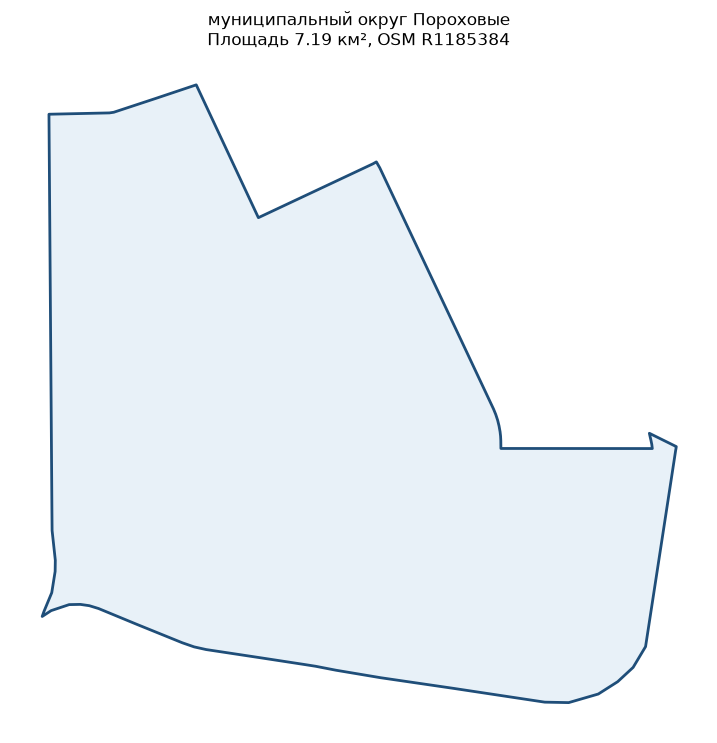

In [6]:
fig, ax = plt.subplots(figsize=(9, 9))
boundary.plot(ax=ax, facecolor="#e8f1f8", edgecolor="#1f4e79", linewidth=2)
ax.set_title(f"{TERRITORY_NAME}\nПлощадь {area_km2:.2f} км², OSM {TERRITORY_OSM_ID}")
ax.set_axis_off()
plt.show()

### 6.2. Дороги, железные дороги и вода

Теги взяты из `pipeline.ipynb` без изменений. Эти слои нужны не для карты,
а для **нарезки кварталов**: дороги и железные дороги работают как барьеры,
вода вырезается из кварталов.

In [7]:
BC_TAGS = {
    "roads": {
        "highway": [
            "construction",
            "crossing",
            "living_street",
            "motorway",
            "motorway_link",
            "motorway_junction",
            "pedestrian",
            "primary",
            "primary_link",
            "raceway",
            "residential",
            "road",
            "secondary",
            "secondary_link",
            "services",
            "tertiary",
            "tertiary_link",
            "track",
            "trunk",
            "trunk_link",
            "turning_circle",
            "turning_loop",
            "unclassified",
        ],
        "service": ["living_street", "emergency_access"],
    },
    "railways": {"railway": "rail"},
    "water": {
        "riverbank": True,
        "reservoir": True,
        "basin": True,
        "dock": True,
        "canal": True,
        "pond": True,
        "natural": ["water", "bay"],
        "waterway": ["river", "canal", "ditch"],
        "landuse": "basin",
        "water": "lake",
    },
}

In [8]:
def load_osm_layer(title, tags, filename, geom_types, keep_columns=()):
    '''Читает слой из raw/ или скачивает его из OSM и сохраняет в EPSG:4326.'''
    path = RAW_DIR / filename

    if path.exists() and not FORCE_REDOWNLOAD:
        layer = gpd.read_file(path)
        print(f"[кэш] {title}: {len(layer)} объектов из {filename}")
    else:
        print(f"[OSM] загружаю слой «{title}» ...")
        layer = ox.features_from_polygon(boundary_wgs.geometry.union_all(), tags=tags)
        layer = layer[layer.geometry.notna()].copy()
        layer = layer[layer.geom_type.isin(geom_types)].reset_index(drop=True)
        if layer.empty:
            raise RuntimeError(f"OSM не вернул объекты для слоя «{title}»")

        columns = ["geometry"] + [column for column in keep_columns if column in layer.columns]
        layer = layer[columns]
        save_geojson(layer, path)

    if layer.crs is None:
        layer = layer.set_crs(4326)
    return layer.to_crs(WORK_CRS)


roads = load_osm_layer(
    "дороги",
    BC_TAGS["roads"],
    "roads.geojson",
    ["LineString", "MultiLineString"],
    keep_columns=("highway", "name"),
)

railways = load_osm_layer(
    "железные дороги",
    BC_TAGS["railways"],
    "railways.geojson",
    ["LineString", "MultiLineString"],
    keep_columns=("railway", "name"),
)

water = load_osm_layer(
    "вода",
    BC_TAGS["water"],
    "water.geojson",
    ["Polygon", "MultiPolygon", "LineString", "MultiLineString"],
    keep_columns=("natural", "water", "landuse"),
)

print(f"Дорог: {len(roads)} линий")
print(f"Железных дорог: {len(railways)} линий")
print(f"Водных объектов: {len(water)}")

[кэш] дороги: 356 объектов из roads.geojson
[кэш] железные дороги: 15 объектов из railways.geojson
[кэш] вода: 11 объектов из water.geojson
Дорог: 356 линий
Железных дорог: 15 линий
Водных объектов: 11


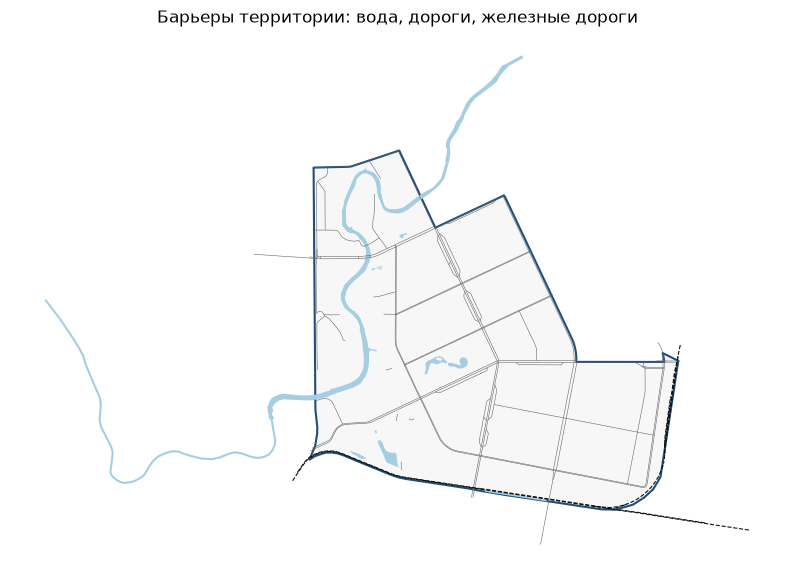

In [9]:
fig, ax = plt.subplots(figsize=(10, 10))
boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.5)
water.plot(ax=ax, color="#a6cee3", edgecolor="none")
roads.plot(ax=ax, color="#666666", linewidth=0.4)
railways.plot(ax=ax, color="#111111", linewidth=0.8, linestyle="--")
ax.set_title("Барьеры территории: вода, дороги, железные дороги")
ax.set_axis_off()
plt.show()

### 6.3. Функциональные зоны (`landuse`)

Функциональные зоны нужны для назначения `land_use` кварталам.
Источник — OSM `landuse`, **это не официальные ПЗЗ**.
Значения, для которых нет правила, будут перечислены ниже и останутся без land use.

In [10]:
functional_zones_path = RAW_DIR / "functional_zones.geojson"

if functional_zones_path.exists() and not FORCE_REDOWNLOAD:
    functional_zones = gpd.read_file(functional_zones_path)
    print(f"[кэш] функциональные зоны: {len(functional_zones)} объектов")
else:
    print("[OSM] загружаю функциональные зоны (landuse) ...")
    zones = ox.features_from_polygon(
        boundary_wgs.geometry.union_all(),
        tags={"landuse": True},
    )
    zones = zones[zones.geometry.notna()].copy()
    zones = zones[zones.geom_type.isin(["Polygon", "MultiPolygon"])].reset_index(drop=True)
    if "landuse" not in zones.columns:
        raise RuntimeError("В ответе OSM нет колонки landuse")
    functional_zones = zones[["geometry", "landuse"]].rename(columns={"landuse": "functional_zone"})
    save_geojson(functional_zones, functional_zones_path)

functional_zones = functional_zones.to_crs(WORK_CRS)
print(f"Функциональных зон: {len(functional_zones)}")
functional_zones["functional_zone"].value_counts().head(20)

[кэш] функциональные зоны: 566 объектов
Функциональных зон: 566


functional_zone
grass                460
retail                30
industrial            22
garages               13
residential           13
commercial            10
construction           6
meadow                 3
railway                3
plant_nursery          1
flowerbed              1
depot                  1
recreation_ground      1
religious              1
brownfield             1
Name: count, dtype: int64

### 6.4. Здания

Из OSM берём только то, что действительно является исходными данными:
контур здания, тип (`building`) и этажность (`building:levels`).
Площади, жилая площадь и население будут **модельными оценками** в разделе 10.

Колонки переименованы в безопасные для GeoJSON:
`building_osm` и `levels_osm`.

In [11]:
buildings_path = RAW_DIR / "buildings.geojson"

if buildings_path.exists() and not FORCE_REDOWNLOAD:
    buildings_raw = gpd.read_file(buildings_path)
    print(f"[кэш] здания: {len(buildings_raw)} объектов")
else:
    print("[OSM] загружаю здания ...")
    raw = ox.features_from_polygon(
        boundary_wgs.geometry.union_all(),
        tags={"building": True},
    )
    raw = raw[raw.geometry.notna()].copy()
    raw = raw[raw.geom_type.isin(["Polygon", "MultiPolygon"])].reset_index(drop=True)

    raw["building_osm"] = raw["building"].astype(str) if "building" in raw.columns else pd.NA
    if "building:levels" in raw.columns:
        raw["levels_osm"] = pd.to_numeric(raw["building:levels"], errors="coerce")
    else:
        raw["levels_osm"] = np.nan

    buildings_raw = raw[["geometry", "building_osm", "levels_osm"]]
    save_geojson(buildings_raw, buildings_path)

buildings_raw = buildings_raw.to_crs(WORK_CRS)
levels_known = buildings_raw["levels_osm"].notna().mean()

print(f"Зданий: {len(buildings_raw)}")
print(f"Доля зданий с известной этажностью: {levels_known:.1%}")
print(f"Доля жилых типов зданий: {buildings_raw['building_osm'].isin(['residential', 'house', 'apartments', 'detached', 'terrace', 'dormitory']).mean():.1%}")

[кэш] здания: 1020 объектов
Зданий: 1020
Доля зданий с известной этажностью: 54.6%
Доля жилых типов зданий: 22.5%


### 6.5. Школы

Из OSM берём расположение школ (`amenity=school`).
Вместимость в OSM почти всегда отсутствует, поэтому она будет восстановлена
по конфигурации BlocksNet — это **модельная оценка**, а не фактическое число мест.

In [12]:
schools_path = RAW_DIR / "school.geojson"

if schools_path.exists() and not FORCE_REDOWNLOAD:
    schools_raw = gpd.read_file(schools_path)
    print(f"[кэш] школы: {len(schools_raw)} объектов")
else:
    print("[OSM] загружаю школы ...")
    raw = ox.features_from_polygon(
        boundary_wgs.geometry.union_all(),
        tags={"amenity": "school"},
    )
    raw = raw[raw.geometry.notna()].copy()
    raw = raw[raw.geom_type.isin(["Polygon", "MultiPolygon", "Point"])].reset_index(drop=True)

    raw["name"] = raw["name"].astype(str) if "name" in raw.columns else pd.NA
    schools_raw = raw[["geometry", "name"]]
    save_geojson(schools_raw, schools_path)

schools_raw = schools_raw.to_crs(WORK_CRS)
print(f"Школ: {len(schools_raw)}")

[кэш] школы: 19 объектов
Школ: 19


### 6.6. Реестр слоёв: что исходное, а что модель

Таблица ниже — краткая версия раздела 3 с фактическим числом объектов.

In [13]:
registry = pd.DataFrame(
    [
        {
            "Слой": "Граница округа",
            "Источник": "OSM / Nominatim, relation R1185384",
            "Единицы": "полигон; м², км²",
            "Тип": "исходные",
            "Факт": f"{area_km2:.2f} км²",
            "Ограничение": "Может отличаться от официальной границы",
        },
        {
            "Слой": "Дороги",
            "Источник": "OSM / Overpass (osmnx)",
            "Единицы": "линии; м",
            "Тип": "исходные",
            "Факт": f"{len(roads)} линий",
            "Ограничение": "Полнота зависит от OSM",
        },
        {
            "Слой": "Железные дороги",
            "Источник": "OSM / Overpass (osmnx)",
            "Единицы": "линии; м",
            "Тип": "исходные",
            "Факт": f"{len(railways)} линий",
            "Ограничение": "Могут быть неполными как барьеры",
        },
        {
            "Слой": "Вода",
            "Источник": "OSM / Overpass (osmnx)",
            "Единицы": "полигоны, линии; м²",
            "Тип": "исходные",
            "Факт": f"{len(water)} объектов",
            "Ограничение": "Берега упрощены",
        },
        {
            "Слой": "Функциональные зоны",
            "Источник": "OSM, тег landuse",
            "Единицы": "полигоны; м²",
            "Тип": "исходные",
            "Факт": f"{len(functional_zones)} объектов",
            "Ограничение": "Не официальные ПЗЗ",
        },
        {
            "Слой": "Здания: контур, тип, этажность",
            "Источник": "OSM, building / building:levels",
            "Единицы": "м², этажи",
            "Тип": "исходные",
            "Факт": f"{len(buildings_raw)} зданий",
            "Ограничение": f"Этажность известна у {levels_known:.0%} зданий",
        },
        {
            "Слой": "Здания: площади и население",
            "Источник": "impute_buildings (BlocksNet)",
            "Единицы": "м², чел.",
            "Тип": "модель",
            "Факт": "будет в разделе 10",
            "Ограничение": "1 этаж при пропуске; 30 м²/чел.; 0.9 — жилая доля",
        },
        {
            "Слой": "Школы: расположение",
            "Источник": "OSM, amenity=school",
            "Единицы": "точки, полигоны",
            "Тип": "исходные",
            "Факт": f"{len(schools_raw)} школ",
            "Ограничение": "Список может быть неполным",
        },
        {
            "Слой": "Школы: вместимость",
            "Источник": "impute_services (BlocksNet)",
            "Единицы": "места",
            "Тип": "модель",
            "Факт": "250 мест по умолчанию",
            "Ограничение": "Фактическая вместимость не из OSM",
        },
        {
            "Слой": "Граф доступности",
            "Источник": "BlocksNet Data v0.0.1, graph_drive.pickle",
            "Единицы": "минуты",
            "Тип": "готовый граф",
            "Факт": "будет в разделе 8",
            "Ограничение": "Автомобиль, без пробок",
        },
        {
            "Слой": "Парки и сады",
            "Источник": "OSM, leisure=park / garden",
            "Единицы": "полигоны; м²",
            "Тип": "исходные (дополнение к pipeline)",
            "Факт": "загружаются в разделе 7.2.1",
            "Ограничение": "Только полигоны; часть зелени может быть без тега",
        },
        {
            "Слой": "Парковки",
            "Источник": "OSM, amenity=parking / parking_space",
            "Единицы": "полигоны; м²",
            "Тип": "исходные (дополнение к pipeline)",
            "Факт": "загружаются в разделе 7.2.1",
            "Ограничение": "Мелкие парковки могут отсутствовать",
        },
    ]
)
registry

,Слой,Источник,Единицы,Тип,Факт,Ограничение
0,Граница округа,"OSM / Nominatim, relation R1185384","полигон; м², км²",исходные,7.19 км²,Может отличаться от официальной границы
1,Дороги,OSM / Overpass (osmnx),линии; м,исходные,356 линий,Полнота зависит от OSM
2,Железные дороги,OSM / Overpass (osmnx),линии; м,исходные,15 линий,Могут быть неполными как барьеры
3,Вода,OSM / Overpass (osmnx),"полигоны, линии; м²",исходные,11 объектов,Берега упрощены
4,Функциональные зоны,"OSM, тег landuse",полигоны; м²,исходные,566 объектов,Не официальные ПЗЗ
5,"Здания: контур, тип, этажность","OSM, building / building:levels","м², этажи",исходные,1020 зданий,Этажность известна у 55% зданий
6,Здания: площади и население,impute_buildings (BlocksNet),"м², чел.",модель,будет в разделе 10,1 этаж при пропуске; 30 м²/чел.; 0.9 — жилая доля
7,Школы: расположение,"OSM, amenity=school","точки, полигоны",исходные,19 школ,Список может быть неполным
8,Школы: вместимость,impute_services (BlocksNet),места,модель,250 мест по умолчанию,Фактическая вместимость не из OSM
9,Граф доступности,"BlocksNet Data v0.0.1, graph_drive.pickle",минуты,готовый граф,будет в разделе 8,"Автомобиль, без пробок"


## 7. Подготовка кварталов

### 7.1. Нарезка кварталов

`preprocess_urban_objects` приводит дороги, железные дороги и воду к линиям и полигонам,
затем `cut_urban_blocks` нарезает территорию на замкнутые кварталы.
Каждому кварталу присваивается целочисленный `block_id` — он будет ключом во всех таблицах.

In [14]:
# Кэш нарезки: результат cut_urban_blocks БЕЗ объединения «пылинок».
CUT_CACHE = PROCESSED_DIR / "blocks_cut.geojson"
BLOCKS_PATH = PROCESSED_DIR / "blocks.geojson"

# True — заново нарезать кварталы из OSM-слоёв.
FORCE_REBUILD_BLOCKS = False

if not CUT_CACHE.exists() and BLOCKS_PATH.exists() and not FORCE_REBUILD_BLOCKS:
    # Одна миграция: в blocks.geojson от прошлого запуска лежит нарезка без объединения.
    print("[миграция] сохраняю готовую нарезку как blocks_cut.geojson")
    save_geojson(gpd.read_file(BLOCKS_PATH), CUT_CACHE)
    print("Если blocks.geojson уже был объединён, поставьте FORCE_REBUILD_BLOCKS = True.")

if CUT_CACHE.exists() and not FORCE_REBUILD_BLOCKS:
    blocks = gpd.read_file(CUT_CACHE)
    blocks = blocks.set_index("block_id")
    blocks.index = pd.Index(blocks.index.astype(int), name="block_id")
    blocks = blocks.to_crs(WORK_CRS)
    print(f"[кэш] нарезка прочитана из {CUT_CACHE.name}: {len(blocks)} шт.")
else:
    print("Готовлю линии и полигоны ...")
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    print(f"Линий: {len(lines)}, полигонов: {len(polygons)}")

    print("Нарезаю кварталы ...")
    blocks = cut_urban_blocks(boundary, lines, polygons)

    # Убираем пустые геометрии и чиним самопересечения
    blocks = blocks[blocks.geometry.notna() & ~blocks.geometry.is_empty].copy()
    blocks["geometry"] = blocks.geometry.buffer(0)
    blocks = blocks[~blocks.geometry.is_empty].copy()
    blocks = add_block_id(blocks)

    save_geojson(blocks, CUT_CACHE)

print(f"Кварталов после нарезки: {len(blocks)}")
print(f"Суммарная площадь: {blocks.area.sum() / 1e6:.2f} км²")
print(f"Медианная площадь: {blocks.area.median():,.0f} м²")

[кэш] нарезка прочитана из blocks_cut.geojson: 131 шт.
Кварталов после нарезки: 131
Суммарная площадь: 7.01 км²
Медианная площадь: 5,069 м²


### 7.1.1. Объединение «кварталов-пылинок»

В `pipeline.ipynb` мелкие кварталы **не фильтруются и не объединяются** — пример оставляет все.
При первом запуске нарезка дала 34 квартала меньше 500 м² (минимальный — 1,5 м²):
это полосы вдоль дорог и технические остатки.

Такие кварталы почти не влияют на население, но создают шум в матрице и на картах.
Поэтому здесь они **объединяются с соседом, имеющим самую длинную общую границу**.
Это отклонение от примера, сделанное по результатам проверки территории.

* Нарезка хранится отдельно — `processed/blocks_cut.geojson`.
* Объединённый слой — `processed/blocks.geojson`, он пересчитывается при каждом запуске.
* Порог задаётся переменной `MIN_BLOCK_AREA_M2 = 500`.
  Если нужно поведение строго как в `pipeline.ipynb`, поставьте порог `0`.
* Номера `block_id` после объединения пересчитываются подряд: `0 … n−1`.

In [15]:
from shapely.ops import unary_union

MIN_BLOCK_AREA_M2 = 500  # 0 — поведение строго как в pipeline.ipynb

block_area_before_merge = blocks.geometry.area
small_ids = list(block_area_before_merge.index[block_area_before_merge < MIN_BLOCK_AREA_M2])
merged_small_count = len(small_ids)


def keep_largest_polygon(geometry):
    '''Возвращает Polygon: для MultiPolygon — крупнейшую часть.'''
    if geometry.geom_type == "Polygon":
        return geometry
    if geometry.geom_type == "MultiPolygon":
        return max(geometry.geoms, key=lambda part: part.area)
    polygons = [
        part for part in getattr(geometry, "geoms", []) if part.geom_type == "Polygon"
    ]
    return max(polygons, key=lambda part: part.area) if polygons else geometry


if merged_small_count >= len(blocks):
    print("Все кварталы меньше порога — объединение пропущено.")
    small_ids = []
    merged_small_count = 0

if small_ids:
    print(f"Кварталов меньше {MIN_BLOCK_AREA_M2} м²: {len(small_ids)} — объединяю с соседями.")

    big_blocks = blocks.loc[~blocks.index.isin(small_ids)]
    small_blocks = blocks.loc[small_ids]

    # Сосед — тот, у кого самая длинная общая граница (для касания ребром длина > 0).
    merge_map = {}
    for small_id, small_geometry in small_blocks.geometry.items():
        shared_borders = big_blocks.geometry.apply(
            lambda geometry: geometry.intersection(small_geometry).length
        )
        best_id = shared_borders.idxmax()
        if shared_borders.loc[best_id] > 0:
            merge_map[int(small_id)] = int(best_id)
        else:
            distances = big_blocks.geometry.distance(small_geometry)
            merge_map[int(small_id)] = int(distances.idxmin())
            print(
                f"  • у квартала {small_id} нет общей границы — "
                f"беру ближайший {merge_map[int(small_id)]}"
            )

    merge_series = pd.Series(merge_map, name="neighbor")
    merged_geometries = {}
    for neighbor_id, group in merge_series.groupby(merge_series):
        sources = [int(neighbor_id)] + list(group.index)
        geometry = unary_union([blocks.geometry.loc[source] for source in sources])
        merged_geometries[int(neighbor_id)] = keep_largest_polygon(geometry)

    blocks_before = len(blocks)
    merged_blocks = blocks.loc[~blocks.index.isin(merge_map.keys())].copy()
    for neighbor_id, geometry in merged_geometries.items():
        merged_blocks.loc[neighbor_id, "geometry"] = geometry

    area_before = float(blocks.area.sum())
    blocks = add_block_id(merged_blocks)
    area_after = float(blocks.area.sum())

    print(f"Кварталов до объединения: {blocks_before}; после: {len(blocks)}")
    print(f"Изменение площади: {100 * (area_after - area_before) / area_before:+.2f}%")
    print("Номера block_id после объединения пересчитаны подряд (0 … n−1).")
else:
    print(f"Кварталов меньше {MIN_BLOCK_AREA_M2} м² нет — объединение не требуется.")

save_geojson(blocks, BLOCKS_PATH)

Кварталов меньше 500 м²: 34 — объединяю с соседями.
  • у квартала 51 нет общей границы — беру ближайший 33
  • у квартала 78 нет общей границы — беру ближайший 75
  • у квартала 91 нет общей границы — беру ближайший 33
  • у квартала 130 нет общей границы — беру ближайший 68
Кварталов до объединения: 131; после: 97
Изменение площади: -0.00%
Номера block_id после объединения пересчитаны подряд (0 … n−1).
💾 blocks.geojson: 97 объектов, 0.11 МБ


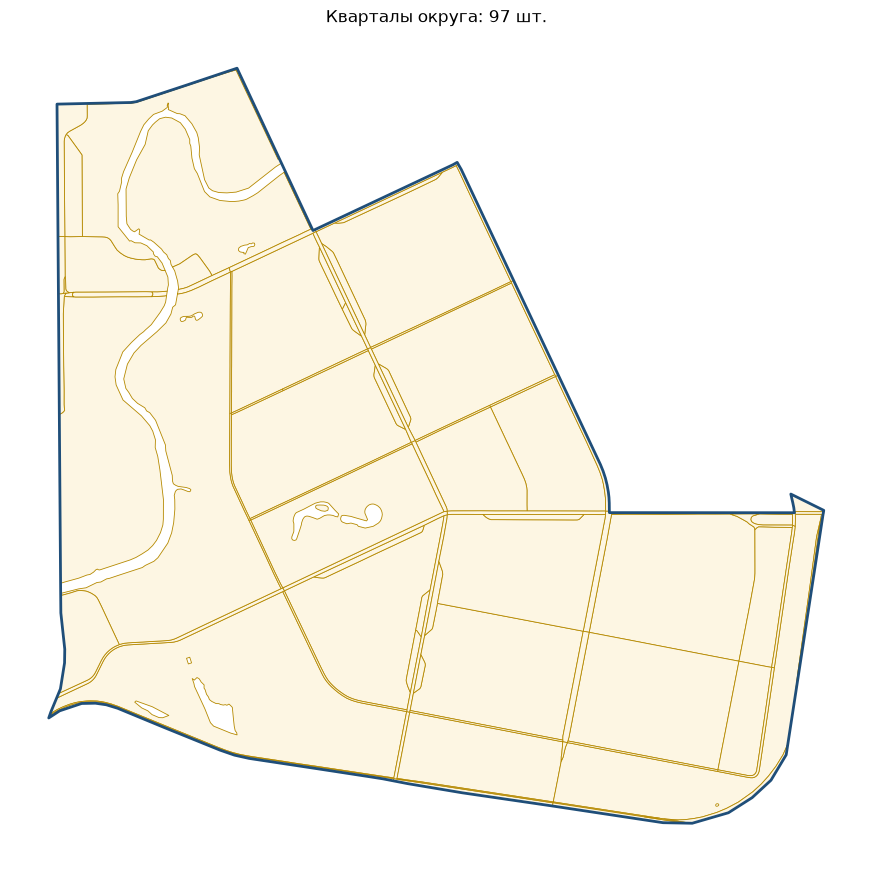

In [16]:
fig, ax = plt.subplots(figsize=(11, 11))
blocks.plot(ax=ax, facecolor="#fdf6e3", edgecolor="#b58900", linewidth=0.6)
boundary.plot(ax=ax, facecolor="none", edgecolor="#1f4e79", linewidth=2)
ax.set_title(f"Кварталы округа: {len(blocks)} шт.")
ax.set_axis_off()
plt.show()

### 7.1.2. Почему железная дорога не разрезала квартал у Хасанского рынка

В слой барьеров попадают только линии `railway=rail` — магистральные пути.
Подъездные пути, ветки и трамвай в запрос из `pipeline.ipynb` не входят,
поэтому смешанный квартал с рынком, «Лентой» и полосой отвода остаётся целым.

Для land use это больше не проблема: полоса отвода приходит отдельным полигоном
`landuse=railway` и в разделе 7.2 получает класс **transport**.
Диагностика ниже показывает, в каких кварталах есть линии `railway=rail`.

Класс квартала выбирается по **наибольшей доле площади**. Поэтому:

* если полоса отвода занимает большую часть квартала — он получает `transport`;
* в смешанном квартале у Хасанского рынка победит `business`, и это ожидаемо:
  торговля там настоящая, а полоса отвода остаётся отдельным полигоном слоя зон.

In [17]:
rail_lines = railways[railways.geom_type.isin(["LineString", "MultiLineString"])][["geometry"]]

try:
    rail_parts = gpd.overlay(
        blocks.reset_index()[["block_id", "geometry"]],
        rail_lines,
        how="intersection",
        keep_geom_type=False,
    )
    rail_parts = rail_parts[rail_parts.geom_type.isin(["LineString", "MultiLineString"])]
    rail_parts["length_m"] = rail_parts.length
    rail_length_by_block = (
        rail_parts.groupby("block_id")["length_m"].sum().sort_values(ascending=False)
    )
    print("Длина railway=rail внутри квартала, топ-10 (м):")
    print(rail_length_by_block.head(10).round(0).to_string())
    print()
    print("Линия railway=rail не разрезает квартал, если не пересекает его целиком.")
except Exception as error:
    print("Диагностика не удалась (на расчёты не влияет):", error)

Длина railway=rail внутри квартала, топ-10 (м):
block_id
90    2699.0
46    2252.0
91    1467.0
95    1315.0
9     1264.0
76     945.0
58     696.0
27     693.0
59     656.0
83     523.0

Линия railway=rail не разрезает квартал, если не пересекает его целиком.


### 7.2. Назначение land use

Правила из `pipeline.ipynb` взяты без изменений и **дополнены** по результатам
проверки территории:

| Что добавлено | Почему |
|---|---|
| `leisure=park`, `leisure=garden` → recreation | Парк Малиновка и зелень у Охты отмечены не через `landuse` |
| `amenity=parking` → transport | Парковки не попадали в слой `landuse` и ошибочно становились зелёными |
| `landuse=railway`, `landuse=depot` → transport | Полоса отвода железной дороги и автобусный парк |
| фильтр узких и мелких газонов | Трава вдоль путей и дорог не должна перекрывать назначение квартала |

> **Это отклонения от `pipeline.ipynb`.** Они сделаны по локальной проверке территории,
> а не являются частью официального примера.

### 7.2.1. Дополнительные зоны: парки и парковки

Проверка территории показала, что только `landuse` недостаточно:

* парк Малиновка и зелёные зоны у Охты в OSM отмечены `leisure=park`, а не `landuse`;
* парковки отмечены `amenity=parking` и не попадают в слой `landuse`.

Поэтому дополнительно загружаются два слоя. Это **отклонение от `pipeline.ipynb`**,
сделанное по результатам проверки территории.

In [18]:
def load_extra_zones(title, tags, filename, zone_column):
    '''Читает дополнительный слой зон из raw/ или скачивает его из OSM.'''
    path = RAW_DIR / filename
    empty = gpd.GeoDataFrame(
        {"functional_zone": pd.Series(dtype="object")},
        geometry=gpd.GeoSeries([], dtype="geometry"),
        crs=WORK_CRS,
    )

    if path.exists() and not FORCE_REDOWNLOAD:
        layer = gpd.read_file(path)
        print(f"[кэш] {title}: {len(layer)} объектов")
    else:
        print(f"[OSM] загружаю {title} ...")
        try:
            layer = ox.features_from_polygon(boundary_wgs.geometry.union_all(), tags=tags)
        except Exception as error:
            print(f"⚠ OSM не вернул слой «{title}»: {error}")
            return empty

        layer = layer[layer.geometry.notna()].copy()
        layer = layer[layer.geom_type.isin(["Polygon", "MultiPolygon"])].reset_index(drop=True)
        if zone_column not in layer.columns:
            print(f"⚠ в ответе OSM нет колонки {zone_column} — слой «{title}» пропущен")
            return empty

        layer = layer[layer[zone_column].notna()].copy()
        layer = layer[["geometry", zone_column]].rename(columns={zone_column: "functional_zone"})
        if layer.empty:
            print(f"⚠ слой «{title}» пуст — пропускаю")
            return empty

        save_geojson(layer, path)

    if layer.crs is None:
        layer = layer.set_crs(4326)
    layer = layer.to_crs(WORK_CRS)
    if "functional_zone" not in layer.columns:
        return empty
    return layer[["geometry", "functional_zone"]]


parks_and_gardens = load_extra_zones(
    "парки и сады",
    {"leisure": ["park", "garden"]},
    "parks_green.geojson",
    "leisure",
)

parkings = load_extra_zones(
    "парковки",
    {"amenity": ["parking", "parking_space"]},
    "parkings.geojson",
    "amenity",
)

print("Парков и садов:", len(parks_and_gardens))
print("Парковок:", len(parkings))

[кэш] парки и сады: 11 объектов
[кэш] парковки: 98 объектов
Парков и садов: 11
Парковок: 98


In [19]:
# --- Объединяем landuse + парки + парковки ---
extra_zones = pd.concat(
    [
        parks_and_gardens[["geometry", "functional_zone"]],
        parkings[["geometry", "functional_zone"]],
    ],
    ignore_index=True,
)
functional_zones_all = gpd.GeoDataFrame(
    pd.concat(
        [functional_zones[["geometry", "functional_zone"]], extra_zones],
        ignore_index=True,
    ),
    geometry="geometry",
    crs=WORK_CRS,
)

# Чиним самопересечения, чтобы маски и пересечения работали предсказуемо
functional_zones_all["geometry"] = functional_zones_all.geometry.buffer(0)
functional_zones_all = functional_zones_all[~functional_zones_all.geometry.is_empty].copy()
functional_zones_all = functional_zones_all[
    functional_zones_all["functional_zone"].notna()
].copy()

# --- Газоны вдоль дорог и путей не должны перекрывать назначение квартала ---
MIN_GRASS_WIDTH_M = 12     # газон уже 12 м считаем придорожной полосой
MIN_GRASS_AREA_M2 = 2000   # и совсем мелкие клумбы тоже не учитываем

green_mask = functional_zones_all["functional_zone"].isin(["grass", "flowerbed"])
narrow_mask = green_mask & functional_zones_all.geometry.buffer(-MIN_GRASS_WIDTH_M / 2).is_empty
small_mask = green_mask & (functional_zones_all.area < MIN_GRASS_AREA_M2)

transport_mask = functional_zones_all["functional_zone"].isin(
    ["railway", "depot", "parking", "parking_space"]
)
transport_zones = functional_zones_all.loc[transport_mask, ["geometry"]]

if len(transport_zones):
    inside_transport = (
        functional_zones_all.loc[green_mask]
        .sjoin(transport_zones, how="inner", predicate="intersects")
        .index.unique()
        .tolist()
    )
else:
    inside_transport = []

drop_mask = narrow_mask | small_mask
drop_mask.loc[inside_transport] = True

print(
    f"Газонов и клумб всего: {int(green_mask.sum())}; "
    f"убрано узких (< {MIN_GRASS_WIDTH_M} м) — {int(narrow_mask.sum())}, "
    f"мелких (< {MIN_GRASS_AREA_M2} м²) — {int(small_mask.sum())}, "
    f"внутри transport — {len(inside_transport)}"
)

functional_zones_all = functional_zones_all.loc[~drop_mask].copy()

LAND_USE_RULES = {
    # правила из pipeline.ipynb
    "commercial": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL,
    "residential": LandUse.RESIDENTIAL,
    "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "religious": LandUse.SPECIAL,
    "flowerbed": LandUse.RECREATION,
    "military": LandUse.SPECIAL,
    "landfill": LandUse.TRANSPORT,
    # дополнения по результатам проверки территории:
    "railway": LandUse.TRANSPORT,
    "depot": LandUse.TRANSPORT,
    "parking": LandUse.TRANSPORT,
    "parking_space": LandUse.TRANSPORT,
    "park": LandUse.RECREATION,
    "garden": LandUse.RECREATION,
}

unknown_zones = sorted(
    set(functional_zones_all["functional_zone"].dropna().astype(str)) - set(LAND_USE_RULES)
)
print("Значения зон без правила (останутся без land use):", unknown_zones)

blocks_lu = assign_land_use(blocks, functional_zones_all, LAND_USE_RULES)
blocks_lu.index = pd.Index(blocks.index, name="block_id")

# Переводим enum в строки, чтобы слой корректно сохранялся в GeoJSON
blocks_lu["land_use"] = blocks_lu["land_use"].apply(
    lambda value: value.value if value is not None else None
)

save_geojson(blocks_lu, PROCESSED_DIR / "blocks_land_use.geojson")
print("Колонки слоя:", list(blocks_lu.columns))
print()
print("Площадь по классам land use, км²:")
print(
    (
        blocks_lu.assign(area_km2=blocks_lu.geometry.area / 1e6)
        .groupby("land_use")["area_km2"]
        .sum()
        .sort_values(ascending=False)
        .round(3)
        .to_string()
    )
)

2026-10-24 10:16:06.697 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: meadow, plant_nursery


Газонов и клумб всего: 461; убрано узких (< 12 м) — 295, мелких (< 2000 м²) — 410, внутри transport — 25
Значения зон без правила (останутся без land use): ['meadow', 'plant_nursery']
💾 blocks_land_use.geojson: 97 объектов, 0.13 МБ
Колонки слоя: ['geometry', 'residential', 'business', 'recreation', 'industrial', 'transport', 'special', 'agriculture', 'land_use', 'share']

Площадь по классам land use, км²:
land_use
residential    3.276
industrial     1.989
recreation     0.898
business       0.471
transport      0.073


In [20]:
land_use_area = blocks_lu.assign(area_m2=blocks_lu.area)
land_use_table = (
    land_use_area.groupby("land_use", dropna=False)
    .agg(
        кварталов=("area_m2", "size"),
        площадь_км2=("area_m2", lambda values: values.sum() / 1e6),
    )
    .sort_values("площадь_км2", ascending=False)
)
land_use_table["доля_площади"] = land_use_table["площадь_км2"] / land_use_table["площадь_км2"].sum()
land_use_table

,кварталов,площадь_км2,доля_площади
land_use,,,
residential,12,3.275667,0.467591
industrial,9,1.988855,0.283903
recreation,9,0.898162,0.128210
business,3,0.471438,0.067296
NaN,51,0.298404,0.042596
transport,13,0.072887,0.010404


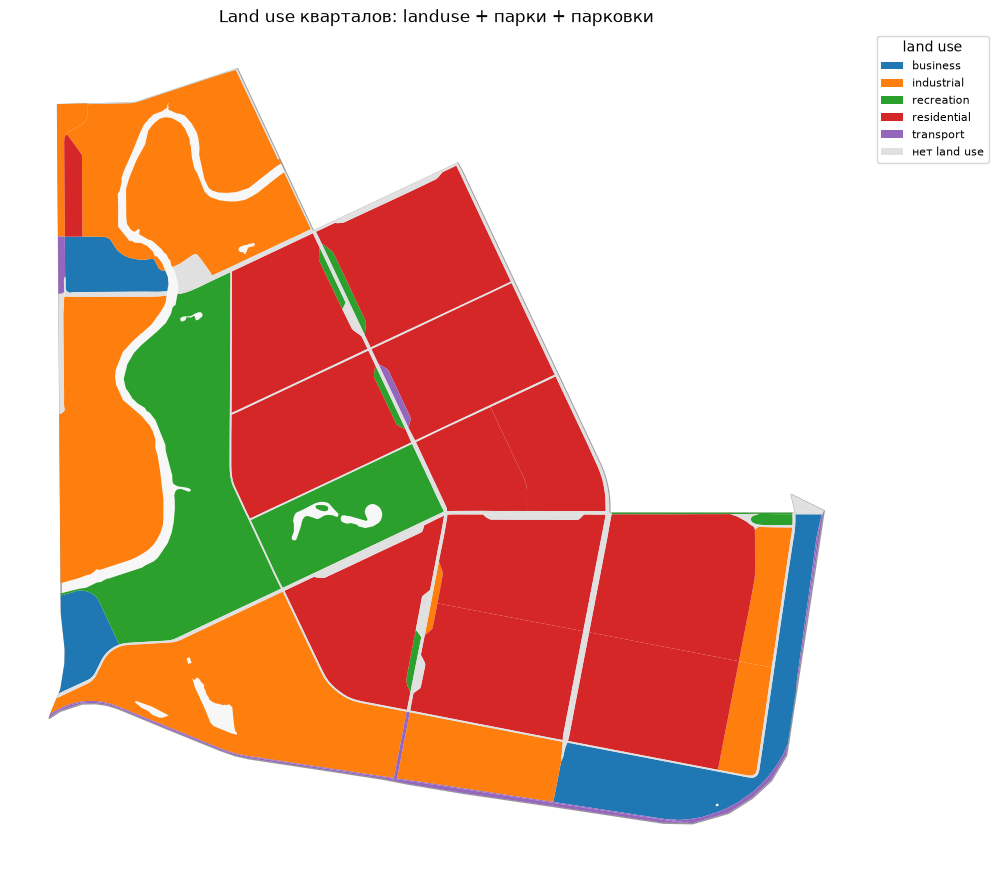

In [21]:
fig, ax = plt.subplots(figsize=(11, 11))
boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#999999", linewidth=1)
blocks_lu.plot(
    column="land_use",
    categorical=True,
    legend=True,
    ax=ax,
    cmap="tab10",
    missing_kwds={"color": "#e0e0e0", "label": "нет land use"},
    legend_kwds={"loc": "upper left", "bbox_to_anchor": (1.01, 1), "fontsize": 8, "title": "land use"},
)
ax.set_title("Land use кварталов: landuse + парки + парковки")
ax.set_axis_off()
plt.show()

### 7.3. Проверка качества кварталов

Смотрим на число кварталов, «кварталы-пылинки», невалидные геометрии и долю площади
без land use. Это не финальная проверка, а контроль перед расчётами.

In [22]:
block_area = blocks.geometry.area

quality = pd.DataFrame(
    [
        ("Кварталов", len(blocks), "шт."),
        ("Суммарная площадь кварталов", block_area.sum() / 1e6, "км²"),
        ("Медианная площадь квартала", block_area.median(), "м²"),
        ("Минимальная площадь квартала", block_area.min(), "м²"),
        ("Кварталов меньше 500 м² после объединения", int((block_area < 500).sum()), "шт."),
        ("Объединено «пылинок» < 500 м²", int(merged_small_count), "шт."),
        ("Невалидных геометрий", int((~blocks.geometry.is_valid).sum()), "шт."),
        ("Пустых геометрий", int(blocks.geometry.is_empty.sum()), "шт."),
        ("Кварталов без land use", int(blocks_lu["land_use"].isna().sum()), "шт."),
        (
            "Доля площади без land use",
            float(block_area[blocks_lu["land_use"].isna()].sum() / block_area.sum()),
            "доля",
        ),
    ],
    columns=["Показатель", "Значение", "Единица"],
)

quality

,Показатель,Значение,Единица
0,Кварталов,97.000000,шт.
1,Суммарная площадь кварталов,7.005413,км²
2,Медианная площадь квартала,7137.331434,м²
3,Минимальная площадь квартала,571.024616,м²
4,Кварталов меньше 500 м² после объединения,0.000000,шт.
5,Объединено «пылинок» < 500 м²,34.000000,шт.
6,Невалидных геометрий,0.000000,шт.
7,Пустых геометрий,0.000000,шт.
8,Кварталов без land use,51.000000,шт.
9,Доля площади без land use,0.042596,доля


## ⛔ ОСТАНОВКА: согласование метрик

Кварталы готовы: граница загружена, территория нарезана, land use назначен,
качество проверено. **Дальше ноутбук намеренно не идёт.**

На этом месте нужно согласовать:

1. **Список услуг.** Сейчас — только школы, как в `pipeline.ipynb`.
   Можно добавить детские сады, поликлиники, магазины и т.д.
2. **Нормативы.** Для школ: 120 мест на 1000 жителей, 15 минут доступности.
3. **Способ передвижения.** Сейчас — автомобиль. Если нужна пешеходная доступность,
   это другой граф и другие выводы.
4. **Набор показателей.** Плотность, морфотипы, площадная доступность — считаем всё,
   как в примере, или только часть.

> **Как продолжить.** В ячейке ниже поменяйте `READY_FOR_CALCULATIONS = False` на `True`,
> запустите эту ячейку, затем продолжайте сверху вниз.
>
> Если запустить ноутбук целиком («Run All»), он остановится на защитном барьере
> в начале раздела 8 — это ожидаемое поведение.

In [24]:
READY_FOR_CALCULATIONS = True  # True — разрешить расчёты, False — остановка по плану

if READY_FOR_CALCULATIONS:
    print("✅ Расчёты разрешены. Продолжайте сверху вниз.")
else:
    print("=" * 72)
    print("⛔ ОСТАНОВКА ПО ПЛАНУ: кварталы и land use готовы")
    print("=" * 72)
    print("Сейчас нужно согласовать список метрик и услуг.")
    print("Чтобы продолжить, поменяйте в этой ячейке READY_FOR_CALCULATIONS = False на True")
    print("и запустите ячейку снова.")
    print()
    print(f"Готовый слой кварталов: {PROCESSED_DIR / 'blocks.geojson'}")
    print(f"Готовый слой land use:  {PROCESSED_DIR / 'blocks_land_use.geojson'}")

✅ Расчёты разрешены. Продолжайте сверху вниз.


## 8. Готовый автомобильный граф

**Источник:** BlocksNet Data, release [`v0.0.1`](https://github.com/IDUclub/blocksnet-data/releases/tag/v0.0.1),
файл `saint_petersburg.zip` → `graph_drive.pickle`.

**Способ передвижения:** автомобиль (`drive`).
**Вес рёбер:** `time_min` — время в **минутах**, по дорожной сети OSM и скоростям IduEdu, без пробок.

Архив целиком весит около 405 МБ, но нужный файл — около 5 МБ.
Ноутбук скачивает **только этот файл** через HTTP Range, не сохраняя архив.
Если автоматическая загрузка не сработает, ниже будет инструкция для ручного варианта.

In [25]:
if not READY_FOR_CALCULATIONS:
    raise RuntimeError(
        "Расчёты остановлены намеренно (этап согласования метрик). "
        "Вернитесь к ячейке «⛔ ОСТАНОВКА», поставьте READY_FOR_CALCULATIONS = True "
        "и запустите её, затем продолжайте сверху вниз."
    )
print("Проверка пройдена: расчёты разрешены.")

Проверка пройдена: расчёты разрешены.


In [26]:
GRAPH_URL = "https://github.com/IDUclub/blocksnet-data/releases/download/v0.0.1/saint_petersburg.zip"
GRAPH_MEMBER = "graph_drive.pickle"
graph_path = RAW_DIR / GRAPH_MEMBER

# Запасной вариант, если автоматическая загрузка недоступна:
# 1) скачайте архив по ссылке GRAPH_URL вручную (около 405 МБ);
# 2) откройте его архиватором;
# 3) извлеките только graph_drive.pickle;
# 4) положите файл в папку RAW_DIR (путь печатается ниже) и запустите эту ячейку снова.
print("Папка для графа:", RAW_DIR)


def download_zip_member(url, member, destination, tail_bytes=262_144, timeout=180):
    '''Скачивает один файл из большого ZIP через HTTP Range, не качая весь архив.'''
    session = requests.Session()
    session.headers.update({"User-Agent": "blocksnet-porokhovye-research/1.0"})

    head = session.head(url, allow_redirects=True, timeout=timeout)
    if head.ok and "Content-Length" in head.headers:
        total = int(head.headers["Content-Length"])
    else:
        probe = session.get(url, headers={"Range": "bytes=0-0"}, timeout=timeout, allow_redirects=True)
        probe.raise_for_status()
        content_range = probe.headers.get("Content-Range", "")
        if "/" not in content_range:
            raise RuntimeError("Сервер не сообщил размер архива")
        total = int(content_range.split("/")[-1])

    tail_start = max(0, total - tail_bytes)
    response = session.get(
        url,
        headers={"Range": f"bytes={tail_start}-{total - 1}"},
        timeout=timeout,
        allow_redirects=True,
    )
    response.raise_for_status()
    if response.status_code != 206:
        raise RuntimeError("Сервер не поддерживает частичную загрузку (HTTP Range)")
    tail = response.content

    eocd = tail.rfind(b"PK\x05\x06")
    if eocd < 0:
        raise RuntimeError("Не найден конец центрального каталога ZIP")

    _, _, _, _, _, cd_size, cd_offset, _ = struct.unpack("<IHHHHIIH", tail[eocd:eocd + 22])
    cd_start_in_tail = cd_offset - tail_start
    if cd_start_in_tail < 0:
        raise RuntimeError("Центральный каталог ZIP не поместился в скачанный хвост архива")
    central_directory = tail[cd_start_in_tail:cd_start_in_tail + cd_size]

    entry = None
    position = 0
    while position + 46 <= len(central_directory):
        if central_directory[position:position + 4] != b"PK\x01\x02":
            break
        fields = struct.unpack("<IHHHHHHIIIHHHHHII", central_directory[position:position + 46])
        method = fields[4]
        compressed_size = fields[8]
        uncompressed_size = fields[9]
        name_length = fields[10]
        extra_length = fields[11]
        comment_length = fields[12]
        local_offset = fields[16]
        name = central_directory[position + 46:position + 46 + name_length].decode("utf-8")
        if name == member:
            entry = {
                "method": method,
                "compressed_size": compressed_size,
                "uncompressed_size": uncompressed_size,
                "local_offset": local_offset,
            }
            break
        position += 46 + name_length + extra_length + comment_length

    if entry is None:
        raise RuntimeError(f"В архиве не найден файл {member}")

    header = session.get(
        url,
        headers={"Range": f"bytes={entry['local_offset']}-{entry['local_offset'] + 29}"},
        timeout=timeout,
        allow_redirects=True,
    )
    header.raise_for_status()
    header_bytes = header.content
    name_length, extra_length = struct.unpack("<HH", header_bytes[26:30])

    data_start = entry["local_offset"] + 30 + name_length + extra_length
    data_end = data_start + entry["compressed_size"] - 1
    data_response = session.get(
        url,
        headers={"Range": f"bytes={data_start}-{data_end}"},
        timeout=timeout,
        allow_redirects=True,
    )
    data_response.raise_for_status()
    if data_response.status_code != 206:
        raise RuntimeError("Сервер не отдал диапазон байт для файла графа")

    payload = data_response.content
    if entry["method"] == 8:
        payload = zlib.decompress(payload, -15)
    elif entry["method"] != 0:
        raise RuntimeError(f"Неподдерживаемый метод сжатия ZIP: {entry['method']}")

    if len(payload) != entry["uncompressed_size"]:
        raise RuntimeError(
            f"Размер после распаковки {len(payload)} байт не совпал "
            f"с ожидаемым {entry['uncompressed_size']} байт"
        )

    destination.write_bytes(payload)
    return destination


if graph_path.exists() and not FORCE_REDOWNLOAD:
    print(f"[кэш] граф уже есть: {graph_path.name}, {file_size_mb(graph_path):.2f} МБ")
else:
    print("[скачивание] graph_drive.pickle из BlocksNet Data v0.0.1 ...")
    try:
        download_zip_member(GRAPH_URL, GRAPH_MEMBER, graph_path)
        print(f"✅ Скачано: {graph_path.name}, {file_size_mb(graph_path):.2f} МБ")
    except Exception as error:
        print("❌ Автоматическая загрузка не удалась.")
        print("Ошибка:", error)
        print()
        print("Запасной вариант:")
        print("1) Скачайте архив вручную:", GRAPH_URL)
        print(f"2) Извлеките {GRAPH_MEMBER} и положите в: {RAW_DIR}")
        print("3) Запустите эту ячейку снова.")

Папка для графа: c:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate\examples\data\porokhovye\raw
[кэш] граф уже есть: graph_drive.pickle, 11.96 МБ


### 8.1. Проверка графа

Проверяем тип графа, систему координат и наличие веса `time_min`.
Если в готовом графе вдруг не окажется `time_min`, но будет `length_meter`,
ноутбук явно предупредит и восстановит время по скорости 30 км/ч —
это будет уже более грубая модельная оценка, а не исходный вес графа.

In [27]:
if not graph_path.exists():
    raise FileNotFoundError(
        f"Файл графа не найден: {graph_path}. "
        "Скачайте graph_drive.pickle вручную и положите его в папку raw/."
    )

print("Загружаю граф (pickle из доверенного источника BlocksNet Data) ...")
with open(graph_path, "rb") as file:
    graph_full = pickle.load(file)

print("Тип графа:", type(graph_full).__name__)
print("Узлов:", graph_full.number_of_nodes())
print("Рёбер:", graph_full.number_of_edges())
print("CRS графа:", graph_full.graph.get("crs"))

sample_edge = next(iter(graph_full.edges(data=True)))
print(
    "Пример атрибутов ребра:",
    {key: value for key, value in sample_edge[2].items() if key != "geometry"},
)

# BlocksNet ожидает целочисленный EPSG. Приводим, если в графе записана строка.
graph_crs_value = graph_full.graph.get("crs")
if graph_crs_value is not None and not isinstance(graph_crs_value, int):
    graph_full.graph["crs"] = int(CRS.from_user_input(graph_crs_value).to_epsg())
    print("CRS графа приведён к EPSG:", graph_full.graph["crs"])

GRAPH_TIME_SOURCE = "time_min (готовый граф BlocksNet Data)"

edges_have_time = all("time_min" in data for _, _, data in graph_full.edges(data=True))
if not edges_have_time:
    if "length_meter" not in sample_edge[2]:
        raise RuntimeError(
            "В графе нет ни time_min, ни length_meter. "
            "Пришлите вывод этой ячейки, чтобы выбрать другой способ расчёта."
        )
    DEFAULT_SPEED_KMH = 30.0
    speed_m_per_min = DEFAULT_SPEED_KMH * 1000 / 60
    for _, _, data in graph_full.edges(data=True):
        data["time_min"] = data["length_meter"] / speed_m_per_min
    GRAPH_TIME_SOURCE = f"length_meter / {DEFAULT_SPEED_KMH:.0f} км/ч (модельная оценка)"
    print("⚠️ В графе не было time_min. Время восстановлено по length_meter.")

print("Источник времени в пути:", GRAPH_TIME_SOURCE)
print("Способ передвижения: автомобиль (drive)")

Загружаю граф (pickle из доверенного источника BlocksNet Data) ...
Тип графа: MultiDiGraph
Узлов: 25894
Рёбер: 59157
CRS графа: 32636
Пример атрибутов ребра: {'length_meter': 25.115, 'time_min': 0.025}
Источник времени в пути: time_min (готовый граф BlocksNet Data)
Способ передвижения: автомобиль (drive)


### 8.2. Обрезка графа по территории

Граф покрывает весь Санкт-Петербург. Чтобы не считать лишние пары,
оставляем только узлы внутри границы округа с буфером **1 км**.
Буфер нужен, чтобы у кварталов на краю территории был доступ к ближайшим дорогам.

In [28]:
GRAPH_BUFFER_M = 1000
graph_crs = graph_full.graph.get("crs", 4326)

clip_geometry = (
    gpd.GeoSeries([boundary_wgs.geometry.union_all()], crs=4326)
    .to_crs(WORK_CRS)
    .buffer(GRAPH_BUFFER_M)
    .to_crs(graph_crs)
    .iloc[0]
)
prepared_clip = prep(clip_geometry)

nodes_in_buffer = []
for node, data in graph_full.nodes(data=True):
    if "x" in data and "y" in data and prepared_clip.contains(Point(data["x"], data["y"])):
        nodes_in_buffer.append(node)

print(f"Узлов в буфере {GRAPH_BUFFER_M} м: {len(nodes_in_buffer)} из {graph_full.number_of_nodes()}")
if len(nodes_in_buffer) < 10:
    raise RuntimeError("В буфере оказалось слишком мало узлов графа. Проверьте CRS графа.")

graph = graph_full.subgraph(nodes_in_buffer).copy()

# IduEdu использует номера узлов графа как индексы строк матрицы смежности.
# После обрезки узлы сохраняют номера из графа всего Петербурга (до ~17 000), а
# IduEdu удаляет «ловушки» (тупиковые компоненты) — номера перестают совпадать с индексами,
# и расчёт матрицы падает (ядро аварийно завершается) или выдаёт мусор.
# Поэтому оставляем крупнейшую сильно связную компоненту и перенумеровываем узлы 0…N−1.
nodes_before_scc = graph.number_of_nodes()
largest_scc = max(nx.strongly_connected_components(graph), key=len)
graph = nx.convert_node_labels_to_integers(graph.subgraph(largest_scc).copy())
print(f"Крупнейшая сильно связная компонента: {graph.number_of_nodes()} из {nodes_before_scc} узлов; узлы перенумерованы 0…N−1")
print("После обрезки — узлов:", graph.number_of_nodes(), "рёбер:", graph.number_of_edges())

if graph.is_directed():
    components = nx.number_weakly_connected_components(graph)
else:
    components = nx.number_connected_components(graph)
print("Связных компонент (слабо связных для ориентированного графа):", components)

with open(PROCESSED_DIR / "graph_drive_clipped.pickle", "wb") as file:
    pickle.dump(graph, file, protocol=pickle.HIGHEST_PROTOCOL)
print(f"💾 graph_drive_clipped.pickle: {file_size_mb(PROCESSED_DIR / 'graph_drive_clipped.pickle'):.2f} МБ")

Узлов в буфере 1000 м: 382 из 25894
Крупнейшая сильно связная компонента: 347 из 382 узлов; узлы перенумерованы 0…N−1
После обрезки — узлов: 347 рёбер: 658
Связных компонент (слабо связных для ориентированного графа): 1
💾 graph_drive_clipped.pickle: 0.15 МБ


💾 graph_edges.geojson: 658 объектов, 0.12 МБ


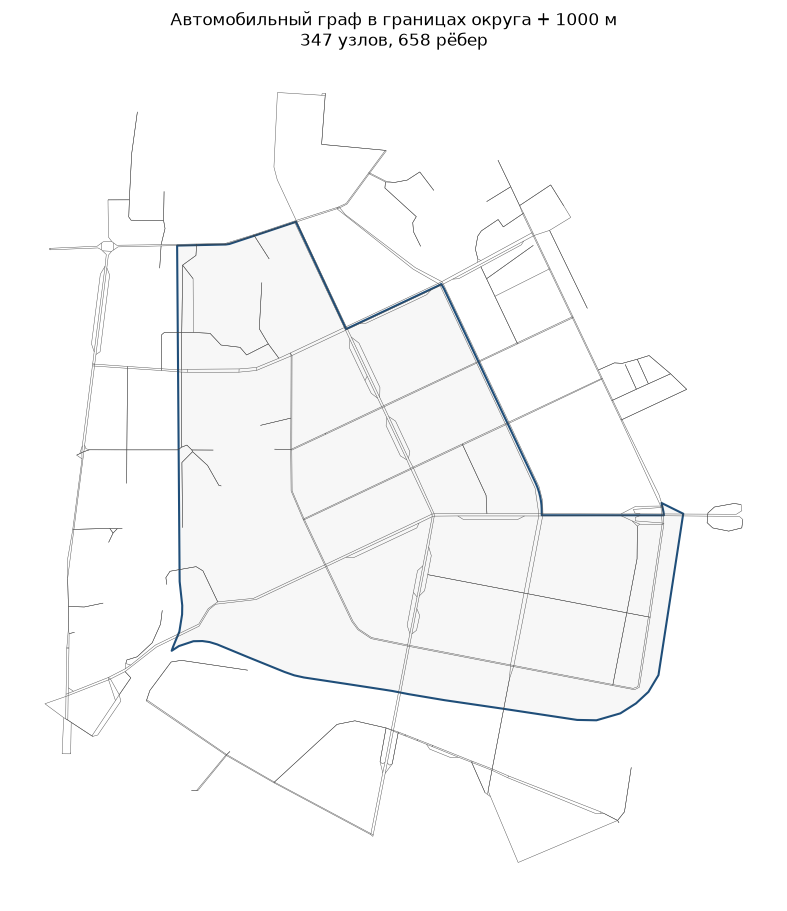

In [29]:
try:
    nodes_gdf, edges_gdf = accessibility_graph_to_gdfs(graph)
    edges_gdf = edges_gdf.reset_index()
    edges_gdf = edges_gdf.rename(columns={edges_gdf.columns[0]: "u", edges_gdf.columns[1]: "v"})
    edges_gdf = edges_gdf[edges_gdf.geometry.notna() & ~edges_gdf.geometry.is_empty].copy()

    if CRS.from_user_input(graph_crs).is_geographic:
        tolerance = 0.0001  # примерно 10 м
    else:
        tolerance = 10.0
    edges_gdf["geometry"] = edges_gdf.geometry.simplify(tolerance)
    edges_gdf = edges_gdf[~edges_gdf.geometry.is_empty].copy()

    save_geojson(edges_gdf[["u", "v", "geometry"]], PROCESSED_DIR / "graph_edges.geojson")

    fig, ax = plt.subplots(figsize=(11, 11))
    boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.5)
    edges_gdf.plot(ax=ax, color="#444444", linewidth=0.3)
    ax.set_title(f"Автомобильный граф в границах округа + {GRAPH_BUFFER_M} м\n"
                 f"{graph.number_of_nodes():,} узлов, {graph.number_of_edges():,} рёбер")
    ax.set_axis_off()
    plt.show()
except Exception as error:
    print("Не удалось сохранить слой рёбер графа (на расчёты это не влияет):", error)

## 9. Матрица времени между кварталами

`calculate_accessibility_matrix` считает время в пути между **центрами кварталов**
по автомобильному графу. Результат — квадратная матрица `N × N`:
строка — откуда, столбец — куда, значение — **минуты**.

Особенности:
* диагональ должна быть равна 0;
* недостижимые пары получают `inf`;
* в время включается подход к ближайшему узлу сети (так устроен IduEdu);
* это **модельная оценка**, а не замеры времени в реальном трафике.

In [30]:
matrix_path = PROCESSED_DIR / "accessibility_matrix.csv"

if matrix_path.exists() and not FORCE_RECALCULATE:
    acc_mx = pd.read_csv(matrix_path, index_col=0)
    acc_mx.index = acc_mx.index.astype(int)
    acc_mx.columns = acc_mx.columns.astype(int)
    acc_mx.index.name = None
    acc_mx.columns.name = None
    print(f"[кэш] матрица прочитана из CSV: {acc_mx.shape[0]} × {acc_mx.shape[1]}")
else:
    print("Считаю матрицу времени ... это самый долгий шаг ноутбука.")
    acc_mx = calculate_accessibility_matrix(
        blocks,
        graph,
        weight_key="time_min",
        dtype=np.float32,
    )
    acc_mx.index.name = None
    acc_mx.columns.name = None
    acc_mx.to_csv(matrix_path, float_format="%.2f")
    print(f"💾 accessibility_matrix.csv: {acc_mx.shape[0]} × {acc_mx.shape[1]}")

print("Размер матрицы:", acc_mx.shape)
print("Совпадает с числом кварталов:", acc_mx.shape[0] == len(blocks))

Считаю матрицу времени ... это самый долгий шаг ноутбука.
💾 accessibility_matrix.csv: 97 × 97
Размер матрицы: (97, 97)
Совпадает с числом кварталов: True


In [31]:
matrix_values = acc_mx.to_numpy(dtype="float64")
off_diagonal_mask = ~np.eye(matrix_values.shape[0], dtype=bool)
off_diagonal = matrix_values[off_diagonal_mask]
reachable = off_diagonal[np.isfinite(off_diagonal)]

share_unreachable = float(np.isinf(off_diagonal).mean()) if off_diagonal.size else float("nan")
median_time = float(np.median(reachable)) if reachable.size else float("nan")
p90_time = float(np.percentile(reachable, 90)) if reachable.size else float("nan")
max_time = float(reachable.max()) if reachable.size else float("nan")

matrix_stats = pd.DataFrame(
    [
        ("Пар кварталов (без диагонали)", off_diagonal.size, "пар"),
        ("Достижимых пар", reachable.size, "пар"),
        ("Доля недостижимых пар", share_unreachable, "доля"),
        ("Медианное время", median_time, "мин"),
        ("90-й процентиль времени", p90_time, "мин"),
        ("Максимальное время", max_time, "мин"),
    ],
    columns=["Показатель", "Значение", "Единица"],
)
matrix_stats

,Показатель,Значение,Единица
0,Пар кварталов (без диагонали),9312.000000,пар
1,Достижимых пар,9312.000000,пар
2,Доля недостижимых пар,0.000000,доля
3,Медианное время,6.962940,мин
4,90-й процентиль времени,9.788437,мин
5,Максимальное время,13.970199,мин


In [32]:
print("Фрагмент матрицы времени, минуты (первые 5 × 5 кварталов):")
acc_mx.iloc[:5, :5].round(1)

Фрагмент матрицы времени, минуты (первые 5 × 5 кварталов):


,0,1,2,3,4
0,0.0,9.1,8.1,6.1,9.0
1,8.6,0.0,7.7,5.7,7.2
2,9.0,7.8,0.0,4.8,6.8
3,8.1,6.8,5.8,0.0,6.6
4,8.6,7.3,7.2,5.7,0.0


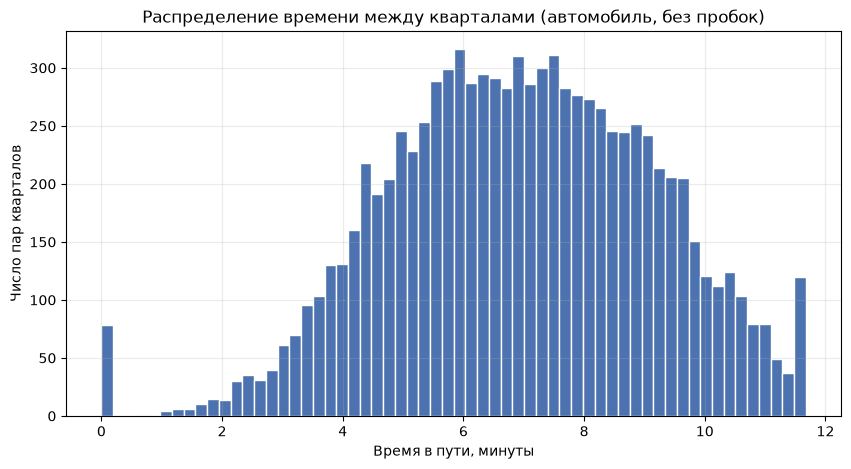

In [33]:
if reachable.size:
    upper = np.percentile(reachable, 99)
    clipped = np.clip(reachable, 0, upper)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(clipped, bins=60, color="#4c72b0", edgecolor="white")
    ax.set_xlabel("Время в пути, минуты")
    ax.set_ylabel("Число пар кварталов")
    ax.set_title("Распределение времени между кварталами (автомобиль, без пробок)")
    ax.grid(alpha=0.25)
    plt.show()
else:
    print("Нет достижимых пар — проверьте граф и границы территории.")

## 10. Здания и население

### 10.1. Исходные признаки → модельные оценки

Из OSM берём:
* `is_living` — является ли здание жилым (по типу `building`);
* `number_of_floors` — этажность из `building:levels`.

Далее `impute_buildings` восстанавливает недостающее:
* `footprint_area` — площадь застройки (по геометрии);
* `build_floor_area` = этажность × площадь застройки;
* `living_area` = 0.9 × площадь этажей для жилых зданий;
* `non_living_area` = площадь этажей − жилая площадь;
* `population` = жилая площадь // 30 м² на человека.

> Всё, что ниже в этом разделе, кроме контура, типа и этажности, — **модельная оценка**.
> Население не взято из Росстата. При пропуске этажности ставится 1 этаж,
> поэтому население и плотность могут быть занижены.

In [34]:
IS_LIVING_TAGS = ["residential", "house", "apartments", "detached", "terrace", "dormitory"]

buildings = buildings_raw.copy()
buildings["is_living"] = buildings["building_osm"].fillna("").astype(str).isin(IS_LIVING_TAGS)
buildings["number_of_floors"] = buildings["levels_osm"]

floors_missing = buildings["number_of_floors"].isna()
floors_missing_count = int(floors_missing.sum())

buildings = buildings[["geometry", "is_living", "number_of_floors"]].copy()
buildings = impute_buildings(
    buildings,
    default_number_of_floors=1,
    default_living_demand=30,
)

save_geojson(buildings, PROCESSED_DIR / "buildings_imputed.geojson")

model_assumptions = pd.DataFrame(
    [
        ("Этажность не указана → 1 этаж", floors_missing_count, "зданий"),
        ("Жилая доля площади этажей", 0.9, "доля"),
        ("Жилая норма", 30, "м²/чел."),
        ("Население", "модель", "чел."),
    ],
    columns=["Допущение", "Значение", "Единица"],
)
model_assumptions

2026-10-24 10:16:50.379 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None
2026-10-24 10:16:50.381 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None
2026-10-24 10:16:50.381 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None
2026-10-24 10:16:50.382 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None
2026-10-24 10:16:50.382 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


💾 buildings_imputed.geojson: 1020 объектов, 0.66 МБ


,Допущение,Значение,Единица
0,Этажность не указана → 1 этаж,463,зданий
1,Жилая доля площади этажей,0.9,доля
2,Жилая норма,30,м²/чел.
3,Население,модель,чел.


In [35]:
print(f"Зданий всего: {len(buildings)}")
print(f"Жилых зданий: {int(buildings['is_living'].sum())}")
print(f"Модельное население: {buildings['population'].sum():,.0f} чел.")
print(f"Суммарная площадь застройки: {buildings['footprint_area'].sum() / 1e6:.2f} км²")
print(f"Суммарная площадь этажей: {buildings['build_floor_area'].sum() / 1e6:.2f} км²")

Зданий всего: 1020
Жилых зданий: 230
Модельное население: 136,053 чел.
Суммарная площадь застройки: 1.08 км²
Суммарная площадь этажей: 5.76 км²


### 10.2. Агрегация зданий по кварталам

Здание относится к кварталу по своей представительной точке (центроиду внутри полигона).
Здания, чья точка не попала ни в один квартал, попадают в «избыточные» —
их число печатается отдельно.

In [36]:
buildings_blocks, excess_buildings = aggregate_objects(blocks, buildings)
buildings_blocks.index = pd.Index(blocks.index, name="block_id")

print(f"Зданий вне кварталов: {len(excess_buildings)}")
print(f"Население в кварталах: {buildings_blocks['population'].sum():,.0f} чел.")
print(f"Кварталов с населением: {int((buildings_blocks['population'] > 0).sum())}")

buildings_blocks_out = buildings_blocks.copy()
buildings_blocks_out.index = pd.Index(blocks.index, name="block_id")
save_geojson(buildings_blocks_out, PROCESSED_DIR / "blocks_buildings.geojson")

2026-10-24 10:16:50.597 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-24 10:16:50.601 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Зданий вне кварталов: 0
Население в кварталах: 136,053 чел.
Кварталов с населением: 13
💾 blocks_buildings.geojson: 97 объектов, 0.13 МБ


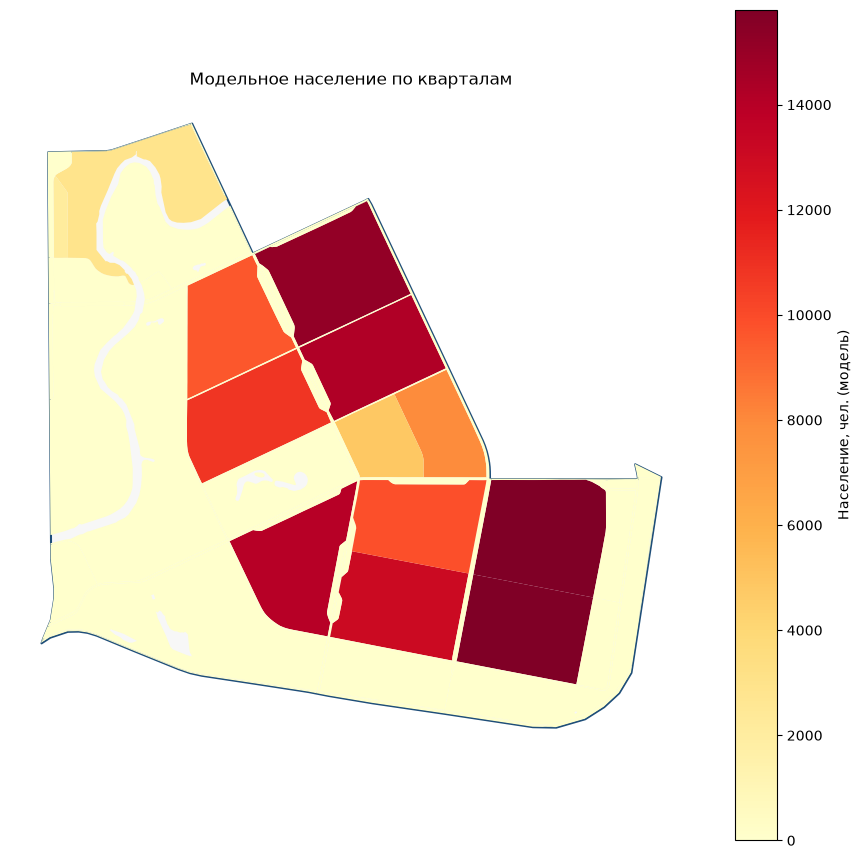

In [37]:
fig, ax = plt.subplots(figsize=(11, 11))
boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.5)
buildings_blocks.plot(
    column="population",
    cmap="YlOrRd",
    legend=True,
    ax=ax,
    missing_kwds={"color": "#eeeeee"},
    legend_kwds={"label": "Население, чел. (модель)"},
)
ax.set_title("Модельное население по кварталам")
ax.set_axis_off()
plt.show()

## 11. Школы и вместимость

Расположение школ — исходные данные OSM.
Вместимость — **модельная оценка**: если в данных нет `capacity`,
BlocksNet ставит минимальную вместимость из своей конфигурации.
Для школ это **250 мест**.

> Важно: это число мест «по умолчанию», а не фактическая вместимость конкретной школы.
> Оно нужно, чтобы методика была воспроизводимой, а не чтобы получить точный норматив.

In [38]:
school_units = service_types_config.units
school_default_capacity = int(
    school_units.loc[school_units["service_type"] == "school", "capacity"].min()
)

schools = schools_raw.copy()
schools["capacity"] = np.nan
capacity_from_source = int(schools["capacity"].notna().sum())

schools = impute_services(schools, "school")
schools.index = pd.Index(schools_raw.index, name=None)

print(f"Школ: {len(schools)}")
print(f"Вместимость из исходных данных: {capacity_from_source} объектов")
print(f"Модельная вместимость по умолчанию: {school_default_capacity} мест")
print(f"Суммарная модельная вместимость: {schools['capacity'].sum():,.0f} мест")

Школ: 19
Вместимость из исходных данных: 0 объектов
Модельная вместимость по умолчанию: 250 мест
Суммарная модельная вместимость: 4,750 мест


In [39]:
schools_blocks, excess_schools = aggregate_objects(blocks, schools)
schools_blocks.index = pd.Index(blocks.index, name="block_id")

schools_blocks_out = schools_blocks.copy()
schools_blocks_out.index = pd.Index(blocks.index, name="block_id")
save_geojson(schools_blocks_out, PROCESSED_DIR / "blocks_schools.geojson")

print(f"Школ вне кварталов: {len(excess_schools)}")
print(f"Кварталов со школами: {int((schools_blocks['capacity'] > 0).sum())}")

2026-10-24 10:16:51.277 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-24 10:16:51.280 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


💾 blocks_schools.geojson: 97 объектов, 0.11 МБ
Школ вне кварталов: 0
Кварталов со школами: 11


In [40]:
schools_table = schools_blocks.loc[schools_blocks["capacity"] > 0, ["count", "capacity"]].copy()
schools_table = schools_table.sort_values("capacity", ascending=False)
schools_table["count"] = schools_table["count"].astype(int)

print(
    f"Кварталов со школами: {len(schools_table)}; "
    f"школ всего: {int(schools_table['count'].sum())}; "
    f"мест (модель): {schools_table['capacity'].sum():,.0f}"
)
schools_table.head(15)

Кварталов со школами: 11; школ всего: 19; мест (модель): 4,750


,count,capacity
block_id,,
16,3,750.0
28,2,500.0
0,2,500.0
43,2,500.0
49,2,500.0
40,2,500.0
33,2,500.0
6,1,250.0
2,1,250.0


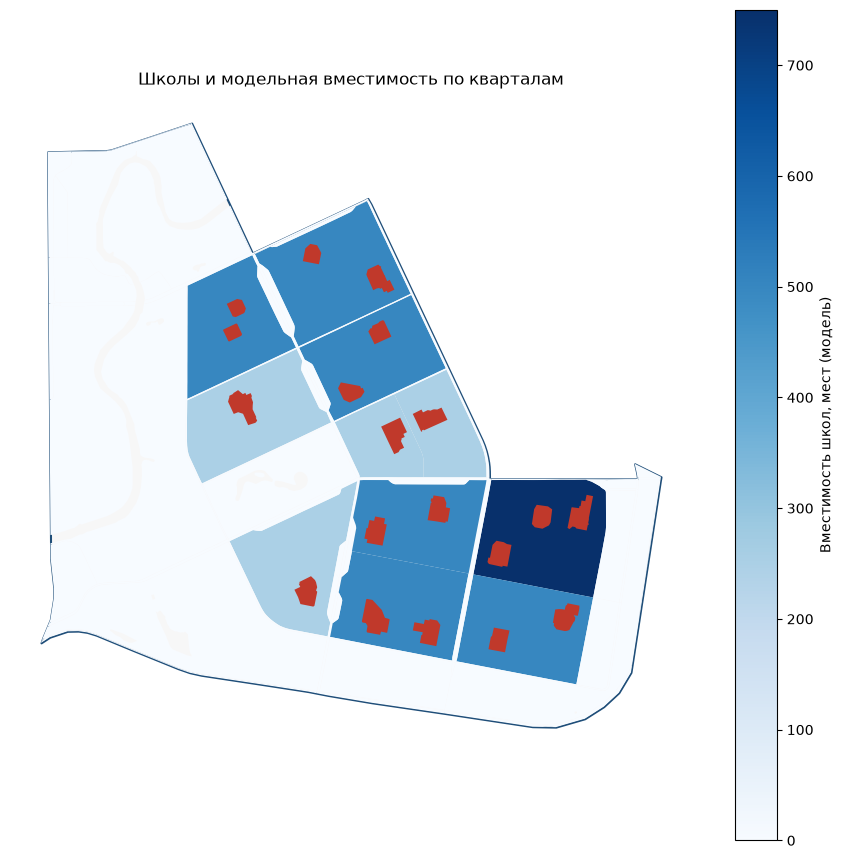

In [41]:
fig, ax = plt.subplots(figsize=(11, 11))
boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.5)
schools_blocks.plot(
    column="capacity",
    cmap="Blues",
    legend=True,
    ax=ax,
    missing_kwds={"color": "#eeeeee"},
    legend_kwds={"label": "Вместимость школ, мест (модель)"},
)
schools.plot(ax=ax, color="#c0392b", markersize=18, zorder=5)
ax.set_title("Школы и модельная вместимость по кварталам")
ax.set_axis_off()
plt.show()

## 12. Показатели BlocksNet

### 12.0. Что BlocksNet умеет считать

BlocksNet — это набор расчётных модулей для города, разбитого на кварталы.
Почти каждая метрика считается **на уровне квартала** и опирается на четыре вещи:
геометрию квартала, здания, услуги (школы, садики, поликлиники) и транспортный граф.

Важно: BlocksNet не «знает» город. Он считает по тем данным, которые ему дали.
Если этажность здания неизвестна или школа не отмечена в OSM — результат будет оценкой,
а не фактом.

| Группа | На какой вопрос отвечает | Основные функции в BlocksNet |
|---|---|---|
| Кварталы и назначение земли | Чем занят каждый квартал: жильё, работа, парк, транспорт | `cut_urban_blocks`, `assign_land_use` |
| Здания и население | Сколько людей живёт и сколько построено | `impute_buildings`, `aggregate_objects` |
| Услуги | Сколько мест в школах и садиках и хватает ли их жителям | `impute_services`, `competitive_provision`, `shared_provision`, `services_count`, `services_density` |
| Транспорт | Сколько минут ехать или идти между кварталами | `calculate_accessibility_matrix`, `area_accessibility`, `mean_accessibility`, `median_accessibility`, `max_accessibility`, `land_use_accessibility`, `relative_accessibility` |
| Плотность застройки | Насколько плотно застроен квартал | `calculate_density_indicators` (FSI, GSI, MXI, L, OSR) |
| Морфотипы | Какой это тип застройки: высотность × плотность × доля жилья | `get_spacematrix_morphotypes`, `get_strelka_morphotypes` |
| Разнообразие и смешанность | Насколько квартал смешанный: жильё, работа, услуги рядом | `shannon_diversity` |
| Центральность | Какие кварталы работают как местные центры | `population_centrality`, `services_centrality` |
| Свободные территории | Где остались незастроенные участки | `get_vacant_areas` |
| Сходство кварталов | Чем кварталы похожи по составу зон | `calculate_land_use_shares`, `land_use_similarity`, `land_use_collocation` |
| Социально-экономические индикаторы | Демография, экология, экономика, инженерия, транспорт | модуль `socio_economic` (нужны внешние данные) |
| Оптимизация и синтез | Что и где достроить, чтобы стало лучше | `optimization`, `synthesis` |

**В этом ноутбуке считается только то, что есть в `pipeline.ipynb`.** Остальные группы
не добавлены сознательно:

* `shared_provision`, `services_count`, `services_density` — у нас только школы,
  а не все услуги, поэтому «обеспеченность всем» считать нечестно;
* `shannon_diversity`, `land_use_similarity`, `land_use_collocation` — нужен полный состав
  зданий и зон, в OSM он неполный, выводы были бы случайными;
* `population_centrality`, `services_centrality`, `get_vacant_areas` — интересные метрики,
  но их нет в примере, и они требуют отдельного согласования;
* `socio_economic` — нужны официальные данные (Росстат, соцопросы), которых у нас нет;
* `optimization` и `synthesis` — это уже сценарии развития, отдельный проект.

### 12.0.1. Все показатели из `pipeline.ipynb`

Ниже — полный список того, что считает пример. Пять строк помечены как
**наше дополнение**: это те же расчётные величины BlocksNet, но пример их не выводит
в итоговую таблицу, а мы выводим для удобства и для дашборда.

| Показатель | Простыми словами | Единица | Что помогает узнать о Пороховых |
|---|---|---|---|
| `land_use` | Класс квартала: жильё, бизнес, промышленность, рекреация, транспорт, специальный, сельское хозяйство | категория | Какая часть округа жилая, какая занята складами, рынком, парками и путями |
| `share` (`land_use_share`) | Доля самой большой зоны внутри квартала | доля 0–1 | Насколько квартал однородный: 1.0 — одна зона, 0.5 — смешанный |
| `lu_share_*` | Доля каждого класса land use в площади квартала | доля 0–1 | Где жильё соседствует с производством, а где с парком |
| `population` | Сколько человек живёт в квартале (модель) | чел. | Где концентрируется население, а где его почти нет |
| `population_density_ha` (наше дополнение) | Плотность населения на гектар | чел./га | Насколько плотно живут люди: двор с пятиэтажками или квартал новостроек |
| `footprint_area` | Площадь застройки, то есть «пятно» домов на земле | м² | Сколько земли реально занято зданиями, а сколько дворами |
| `build_floor_area` | Площадь этажей: сумма всех этажей всех зданий | м² | Общий «объём» застройки — сколько квадратных метров здесь построено |
| `living_area` | Жилая площадь | м² | Сколько жилья есть в квартале |
| `fsi` | Floor Space Index: площадь этажей / площадь квартала | безразмерный | Плотность застройки. 0.5 — малоэтажный район, 2–3 — плотный город |
| `gsi` | Ground Space Index: площадь застройки / площадь квартала | 0–1 | Насколько квартал «закрыт» домами: 0.2 — свободно, 0.4+ — плотно |
| `mxi` | Доля жилой площади в площади этажей | 0–1 | Жилой это квартал или офисно-складской |
| `l` | Средняя этажность | этажи | Одноэтажные склады, пятиэтажки или высотки |
| `osr` | Open Space Ratio: свободная площадь / площадь этажей | безразмерный | Сколько дворов и зелени приходится на каждый квадратный метр этажей |
| `share_living` | Жилая площадь / площадь застройки | 0–1 | Насколько застройка «жилая» |
| `share_non_living` | Нежилая площадь / площадь застройки | 0–1 | Сколько нежилых площадей: магазины, склады, офисы |
| `cluster`, `morphotype` (Spacematrix) | Номер кластера и словесный тип застройки | категория | Тип морфологии: например, «среднеэтажная высокой плотности» |
| `morphotype` (Strelka) | Альтернативный тип застройки по другой методике | категория | Проверка того же вывода второй типологией |
| `capacity` (школы) | Сколько мест в школах квартала (модель, 250 на школу) | мест | Где расположены школы и какая у них расчётная ёмкость |
| `demand` | Сколько мест нужно по нормативу 120 на 1000 жителей | мест | Сколько детей «по нормативу» живёт в квартале |
| `demand_within` (наше дополнение) | Спрос, покрытый школами в пределах 15 минут | мест | Какая часть детей формально имеет школу рядом |
| `demand_without` (наше дополнение) | Спрос, покрытый только школами дальше 15 минут | мест | Какая часть детей едет далеко |
| `capacity_within` (наше дополнение) | Вместимость школ, доступных за 15 минут | мест | Сколько мест реально «достаётся» кварталу |
| `capacity_without` (наше дополнение) | Вместимость школ дальше 15 минут | мест | Резерв, который формально не входит в норматив |
| `provision_strong` | Доля спроса, покрытая в пределах 15 минут | 0–1 | Формальная обеспеченность: 1.0 — мест хватает, 0.5 — половина спроса не покрыта |
| `provision_weak` | То же, но с учётом школ за пределами 15 минут. **В текущей версии совпадает с `provision_strong`:** при глубине 1 BlocksNet распределяет только связи в пределах 15 минут | 0–1 | Насколько ситуацию спасают школы в соседних кварталах |
| Матрица времени | Время в пути между каждой парой кварталов | минуты | Насколько округ «компактный»: медиана, 90-й процентиль, доля недостижимых пар |
| `area_accessibility` | Среднее время до всех кварталов округа, взвешенное по площади | минуты | Насколько квартал удобно расположен относительно всего округа |
| `buildings_count` | Число зданий в квартале | шт. | Плотность объектов и проверка агрегации |
| `summary.json`, `summary.csv` | Сводные цифры по территории | разные | Быстрый «паспорт» округа для отчёта и дашборда |

### 12.0.2. Как читать эти числа

Ни одна из этих цифр не является официальной статистикой. Это **согласованный способ
сравнить кварталы между собой** при текущих данных и допущениях.

**Плотность**

* `fsi` ниже 0.5 — малоэтажная застройка, много свободной земли.
* `fsi` 0.5–1.5 — типичные жилые кварталы 5–9 этажей.
* `fsi` выше 2 — плотная застройка, обычно новостройки или центр.
* `gsi` 0.15–0.25 — свободная планировка, много дворов.
* `gsi` выше 0.4 — дома стоят плотно, дворов мало.
* `l` 2–4 — склады, гаражи, малоэтажное; 5–9 — «панельки»; 12+ — высотки.
* `osr` чем больше, тем больше свободного места на единицу этажей.

**Население и школы**

* `population` — модель: жилая площадь делится на 30 м² на человека.
  Если у здания не указана этажность, ставится 1 этаж, поэтому население скорее занижено.
* `provision_strong = 1.0` — формально мест хватает; `0.5` — покрыта половина спроса.
* `provision_strong` может быть пустым (`NaN`). Это не ноль: в квартале нет жителей,
  а значит и спроса. Такие кварталы нельзя красить в «плохую» обеспеченность.

**Транспорт**

* Медиана времени 5–10 минут — округ компактный.
* `area_accessibility` 10–15 минут — квартал близок ко всему округу; 25+ — окраина.
* Всё это **автомобиль без пробок**. Для школ и садиков правильнее пешеходная доступность,
  поэтому обеспеченность может быть завышена.

**Морфотипы**

* Названия кластеров условны и зависят от набора кварталов: «mid-rise high-density residential»
  — это не официальный термин, а описание похожих кварталов внутри нашей выборки.
* Кварталы без застройки (склады, парки, пустыри) остаются без морфотипа — это нормально.

**Чего числа не говорят**

* Сколько именно детей учится в каждой школе.
* Насколько реально загружены школы и как далеко дети ходят пешком.
* Какая это земля по документам: `landuse` из OSM — не ПЗЗ и не кадастр.

### 12.0.3. Проверка: все показатели примера посчитаны

Таблица соответствия «показатель из `pipeline.ipynb` → где считается → как показан».
Если что-то не считается, это видно сразу.

| Показатель из примера | Раздел ноутбука | Колонка / файл | Как показан |
|---|---|---|---|
| Land use кварталов | 7.2 | `land_use`, `share`, доли по классам | таблица и карта |
| Матрица времени | 9 | `accessibility_matrix.csv` | статистика, гистограмма, фрагмент матрицы |
| Население и площади зданий | 10.1 | `population`, `footprint_area`, `build_floor_area`, `living_area` | печать итогов, таблица допущений |
| Агрегация зданий по кварталам | 10.2 | `blocks_buildings.geojson` | карта населения |
| Школы и вместимость | 11 | `capacity` | печать, таблица по кварталам, карта |
| Конкурентная обеспеченность | 12.1 | `demand`, `provision_strong`, `provision_weak` | печать, две карты (совпадут — см. 12.1), таблица связей |
| Плотность (FSI, GSI, MXI, L, OSR) | 12.2 | `density_df` | `describe()`, карты FSI и GSI |
| Морфотипы Spacematrix | 12.3 | `cluster`, `morphotype` | частоты, таблица кластеров, карта |
| Морфотипы Strelka | 12.4 | `morphotype` | частоты, карта |
| Площадная доступность | 12.5 | `area_accessibility` | `describe()`, карта |
| Итоговый слой | 13 | `blocks_results.geojson` | список колонок, таблица по кварталам |
| Сводка | 13 | `summary.json`, `summary.csv` | таблица и JSON |
| Проверки | 14 | `checks_df` | чек-лист и 4 карты |
| Выводы | 15 | — | текст с автоматическими цифрами |

**Наши дополнения, которых нет в примере** (помечены в разделах 7 и 16):

* объединение кварталов меньше 500 м²;
* парки (`leisure=park/garden`) и парковки (`amenity=parking`) в слое зон;
* правила `railway`, `depot` → `transport` и фильтр узких газонов;
* колонка `population_density_ha` и разбивка спроса `demand_within/without`,
  `capacity_within/without` в итоговом слое — это те же данные BlocksNet, просто
  выведены в таблицу для дашборда.

### 12.1. Конкурентная обеспеченность школами

Параметры берутся из конфигурации BlocksNet для услуги `school`:
* норматив — **120 мест на 1000 жителей**;
* доступность — **15 минут**;
* конкуренция: жители распределяются по ближайшим школам в пределах доступности.

`provision_strong` — доля спроса, покрытая в пределах доступности.
`provision_weak` — по замыслу то же, но с учётом связей за пределами доступности
(на практике при глубине 1 совпадает с `provision_strong`, см. ниже).

> **Ограничение.** 15 минут считаются по **автомобильному** графу.
> Школьники обычно ходят пешком, поэтому это не нормативная пешеходная доступность.

**Почему две карты обеспеченности могут выглядеть одинаково.**
В BlocksNet 1.0.0a9 по умолчанию `max_depth = 1`: спрос распределяется только по школам
в пределах 15 минут, поэтому спрос «за пределами доступности» не возникает и
`provision_weak` совпадает с `provision_strong`. Различие появилось бы при `max_depth = 2`,
но это уже другая методика, и мы её не используем — в `pipeline.ipynb` поведение такое же.

> **Почему 29 % нельзя читать как «школ не хватает».**
> В OSM нет вместимости школ, поэтому всем 19 школам поставлено минимальное значение
> **250 мест**. Реальные школы Петербурга обычно рассчитаны на 600–1200 учеников:
> при 600 местах это 11 400 мест, при 1200 — 22 800. Это дало бы ориентировочно
> **70–100 %** расчётного спроса (простая арифметика, а не пересчёт модели).
>
> Второй эффект: BlocksNet сначала покрывает спрос **собственными** местами квартала.
> Так как мест в целом меньше спроса, вся вместимость расходуется «на себя»,
> файл `provision_links.csv` остаётся пустым, и перераспределения между кварталами нет.
> Поэтому карта показывает отношение «свои места / свой спрос», а не 15-минутную
> доступность. Итог: **29 % — нижняя граница, а не факт**.
>
> **Население — модель.** 136 053 чел. против официальных ~115–120 тыс. чел.
> по округу: модель выше на 13–18 %.

In [42]:
school_demand_per_1000 = int(service_types_config["school"]["demand"])
school_accessibility_min = int(service_types_config["school"]["accessibility"])

prov_input = pd.DataFrame(index=blocks.index)
prov_input["population"] = buildings_blocks["population"].reindex(blocks.index).fillna(0)
prov_input["capacity"] = (
    schools_blocks["capacity"].reindex(blocks.index).fillna(0).round().astype(int)
)

print(f"Норматив: {school_demand_per_1000} мест на 1000 жителей")
print(f"Доступность: {school_accessibility_min} минут (автомобиль)")
print(f"Жителей: {prov_input['population'].sum():,.0f}")
print(f"Мест в школах: {prov_input['capacity'].sum():,.0f}")
print(f"Расчётный спрос: {math.ceil(prov_input['population'].sum() / 1000 * school_demand_per_1000):,.0f} мест")

prov_df, links_df = competitive_provision(
    prov_input,
    acc_mx,
    accessibility=school_accessibility_min,
    demand=school_demand_per_1000,
)

prov_df.index.name = "block_id"
links_df.to_csv(PROCESSED_DIR / "provision_links.csv", index=False, encoding="utf-8-sig")

strong_total = float(provision_strong_total(prov_df))
weak_total = float(provision_weak_total(prov_df))

print(f"Обеспеченность (strong): {strong_total:.1%}")
print(f"Обеспеченность (weak):   {weak_total:.1%}")
print(f"Связей школа — квартал: {len(links_df)}")

if np.allclose(
    prov_df["provision_strong"].fillna(0), prov_df["provision_weak"].fillna(0)
):
    print("ℹ provision_weak = provision_strong: при глубине 1 BlocksNet учитывает")
    print("  только школы в пределах 15 минут.")

2026-10-24 10:16:51.738 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-24 10:16:51.739 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-24 10:16:51.755 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-24 10:16:51.758 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-24 10:16:51.801 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Норматив: 120 мест на 1000 жителей
Доступность: 15 минут (автомобиль)
Жителей: 136,053
Мест в школах: 4,750
Расчётный спрос: 16,327 мест
Обеспеченность (strong): 29.1%
Обеспеченность (weak):   29.1%
Связей школа — квартал: 0
ℹ provision_weak = provision_strong: при глубине 1 BlocksNet учитывает
  только школы в пределах 15 минут.


In [43]:
links_table = links_df.reset_index()
links_table.columns = ["Квартал спроса", "Школа (квартал)", "Распределено спроса, мест"]
links_table = links_table.sort_values("Распределено спроса, мест", ascending=False)

print(f"Связей «квартал спроса → школа»: {len(links_table)}")
print(f"Школ задействовано: {links_table['Школа (квартал)'].nunique()}")
print(f"Кварталов со спросом: {links_table['Квартал спроса'].nunique()}")
links_table.head(15)

Связей «квартал спроса → школа»: 0
Школ задействовано: 0
Кварталов со спросом: 0


,Квартал спроса,Школа (квартал),"Распределено спроса, мест"


💾 blocks_provision.geojson: 97 объектов, 0.13 МБ


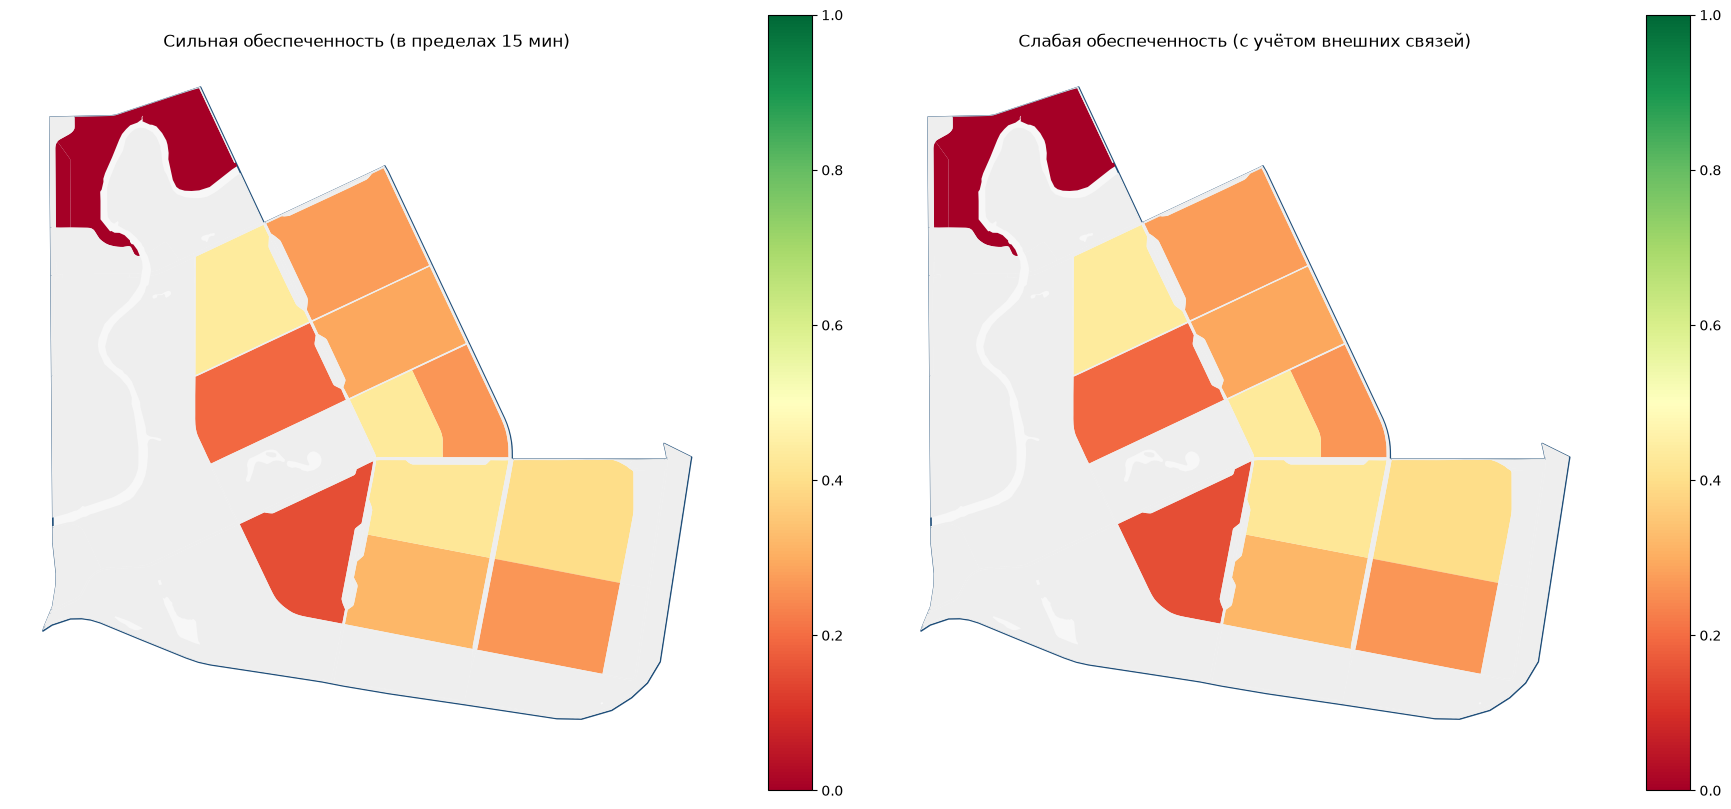

In [44]:
blocks_provision = blocks.join(prov_df)
blocks_provision_out = blocks_provision.copy()
blocks_provision_out.index = pd.Index(blocks.index, name="block_id")
save_geojson(blocks_provision_out, PROCESSED_DIR / "blocks_provision.geojson")

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

boundary.plot(ax=axes[0], facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.2)
blocks_provision.plot(
    column="provision_strong",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    legend=True,
    ax=axes[0],
    missing_kwds={"color": "#eeeeee"},
)
axes[0].set_title("Сильная обеспеченность (в пределах 15 мин)")
axes[0].set_axis_off()

boundary.plot(ax=axes[1], facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.2)
blocks_provision.plot(
    column="provision_weak",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    legend=True,
    ax=axes[1],
    missing_kwds={"color": "#eeeeee"},
)
axes[1].set_title("Слабая обеспеченность (с учётом внешних связей)")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

### 12.2. Плотность застройки

Показатели из `pipeline.ipynb`:

| Показатель | Смысл | Единица |
|---|---|---|
| `fsi` | Floor Space Index, площадь этажей / площадь квартала | безразмерный |
| `gsi` | Ground Space Index, площадь застройки / площадь квартала | безразмерный, 0–1 |
| `mxi` | доля жилой площади в площади этажей | безразмерный, 0–1 |
| `l` | средняя этажность (площадь этажей / площадь застройки) | этажи |
| `osr` | Open Space Ratio, свободная площадь / площадь этажей | безразмерный |
| `share_living`, `share_non_living` | доли жилой и нежилой площади | безразмерные |

Все значения — **модельные**, потому что зависят от восстановленных площадей и этажности.

In [45]:
buildings_blocks["site_area"] = blocks.geometry.area
density_df = calculate_density_indicators(buildings_blocks)
density_df.index.name = "block_id"

density_columns = [
    "site_area",
    "footprint_area",
    "build_floor_area",
    "living_area",
    "fsi",
    "gsi",
    "mxi",
    "l",
    "osr",
    "share_living",
    "share_non_living",
]
density_df[density_columns].describe().T

c:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count,mean,std,min,25%,50%,75%,max
site_area,97.0,7.222075e+04,136767.689189,571.024616,3838.684240,7137.331434,28318.647793,6.138649e+05
footprint_area,97.0,1.113567e+04,22849.360988,0.000000,0.000000,0.000000,3622.301064,1.227765e+05
build_floor_area,97.0,5.933240e+04,145814.259570,0.000000,0.000000,0.000000,3622.301064,5.771253e+05
living_area,97.0,4.211384e+04,119091.570865,0.000000,0.000000,0.000000,0.000000,4.744976e+05
fsi,97.0,2.368379e-01,0.543973,0.000000,0.000000,0.000000,0.127912,2.750352e+00
gsi,97.0,4.685043e-02,0.080220,0.000000,0.000000,0.000000,0.097254,2.779087e-01
mxi,28.0,3.576661e-01,0.397460,0.000000,0.000000,0.000000,0.808736,8.511446e-01
l,28.0,4.741300e+00,4.106056,1.000000,1.023387,2.929380,8.319285,1.578191e+01
osr,97.0,inf,NaN,0.300226,6.817861,NaN,NaN,inf
share_living,28.0,3.128401e+00,3.741784,0.000000,0.000000,0.000000,6.859298,1.146299e+01


c:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate\.venv\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: NaN of Infinity value found. Skipped. Further messages of this type will be suppressed.
  ogr_write(


💾 blocks_density.geojson: 97 объектов, 0.13 МБ


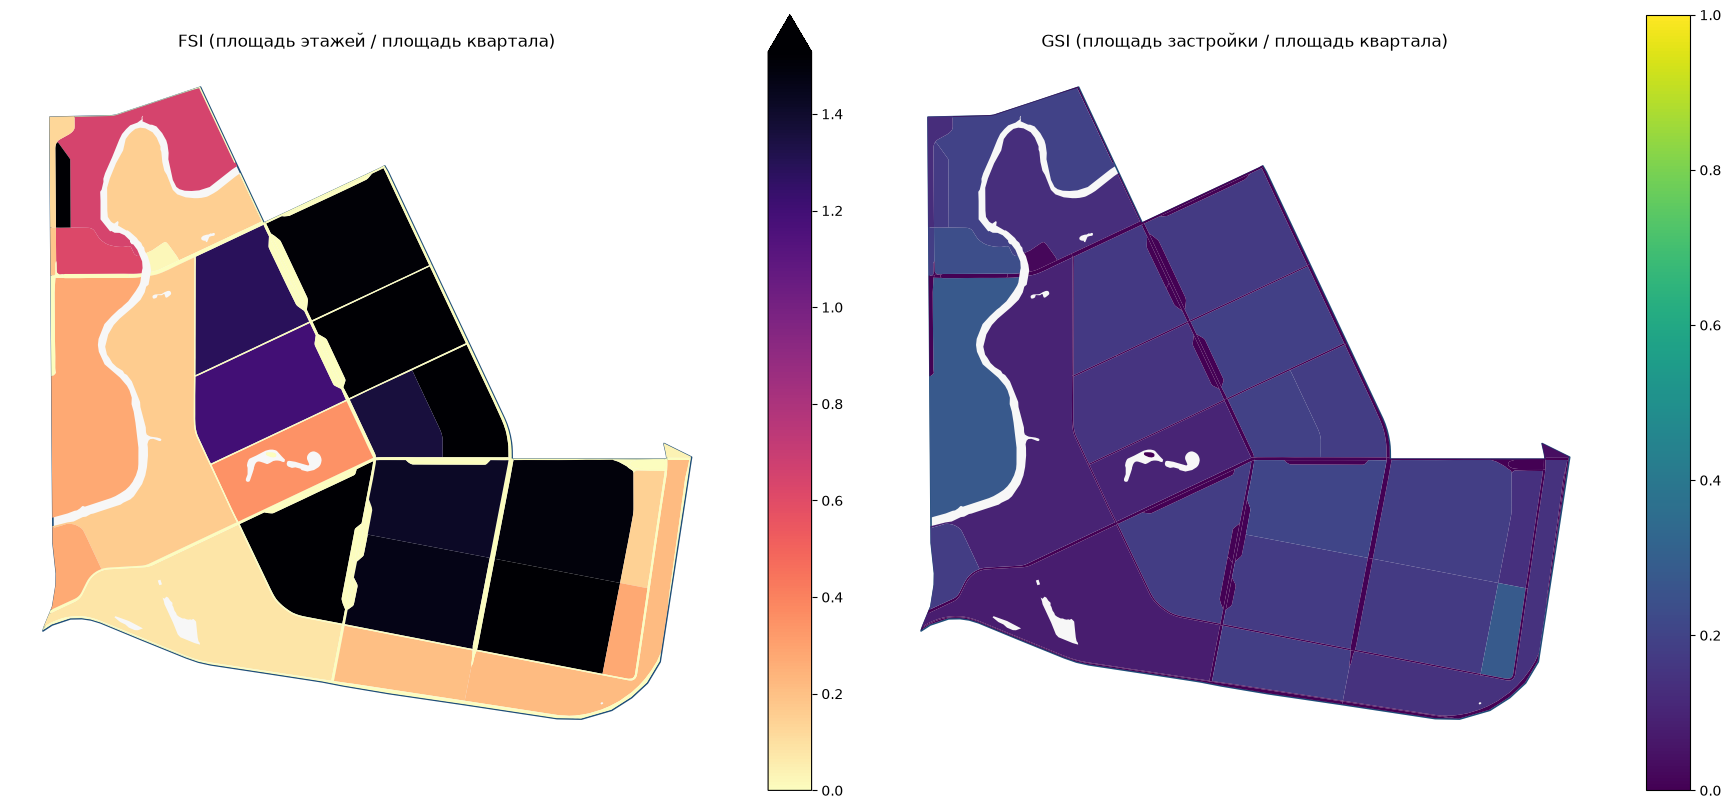

In [46]:
blocks_density = blocks.join(density_df[density_columns])
blocks_density_out = blocks_density.copy()
blocks_density_out.index = pd.Index(blocks.index, name="block_id")
save_geojson(blocks_density_out, PROCESSED_DIR / "blocks_density.geojson")

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
fsi_cap = float(np.nanpercentile(blocks_density["fsi"], 95)) if len(blocks_density) else 1.0

boundary.plot(ax=axes[0], facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.2)
blocks_density.plot(
    column="fsi",
    cmap="magma_r",
    vmax=max(fsi_cap, 0.1),
    legend=True,
    ax=axes[0],
    missing_kwds={"color": "#eeeeee"},
)
axes[0].set_title("FSI (площадь этажей / площадь квартала)")
axes[0].set_axis_off()

boundary.plot(ax=axes[1], facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.2)
blocks_density.plot(
    column="gsi",
    cmap="viridis",
    vmin=0,
    vmax=1,
    legend=True,
    ax=axes[1],
    missing_kwds={"color": "#eeeeee"},
)
axes[1].set_title("GSI (площадь застройки / площадь квартала)")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

### 12.3. Морфотипы Spacematrix

Spacematrix кластеризует **застроенные** кварталы (`fsi > 0`) по `l`, `fsi` и `mxi`
на 11 групп и подписывает кластеры словами вроде `mid-rise high-density residential`.

Важно:
* кварталы без застройки получают пустой морфотип — это нормально;
* число кластеров уменьшается, если застроенных кварталов меньше 11;
* результат зависит от случайного состояния `random_state=42` и от модельных `fsi/mxi`.

In [47]:
developed_count = int((density_df["fsi"] > 0).sum())
n_clusters = int(max(1, min(11, developed_count)))
print(f"Застроенных кварталов: {developed_count}, кластеров: {n_clusters}")

if developed_count >= 1:
    spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(
        density_df,
        n_clusters=n_clusters,
        random_state=42,
    )
else:
    spacematrix_df = density_df.copy()
    spacematrix_df["cluster"] = np.nan
    spacematrix_df["morphotype"] = np.nan
    spacematrix_clusters = pd.DataFrame()

spacematrix_df.index.name = "block_id"
print("Морфотипы Spacematrix:")
spacematrix_df["morphotype"].value_counts(dropna=False)

Застроенных кварталов: 28, кластеров: 11
Морфотипы Spacematrix:


morphotype
NaN                                     69
low-rise low-density non-residential    14
high-mid-rise residential               11
mid-rise low-density mixed-use           1
high-rise high-density residential       1
mid-rise low-density non-residential     1
Name: count, dtype: int64

In [48]:
spacematrix_clusters

,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.125538,0.205401,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
1,8.975329,1.601379,0.829133,high-mid-rise,None,residential,high-mid-rise residential
2,15.781908,2.750352,0.726337,high-rise,high-density,residential,high-rise high-density residential
3,3.253957,0.647088,0.461674,mid-rise,low-density,mixed-use,mid-rise low-density mixed-use
4,7.006635,1.387682,0.710147,high-mid-rise,None,residential,high-mid-rise residential
5,2.604803,0.620109,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
6,7.786528,1.243542,0.805442,high-mid-rise,None,residential,high-mid-rise residential
7,3.531936,0.350550,0.000000,mid-rise,low-density,non-residential,mid-rise low-density non-residential
8,1.000000,0.058477,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential


💾 blocks_spacematrix.geojson: 97 объектов, 0.11 МБ


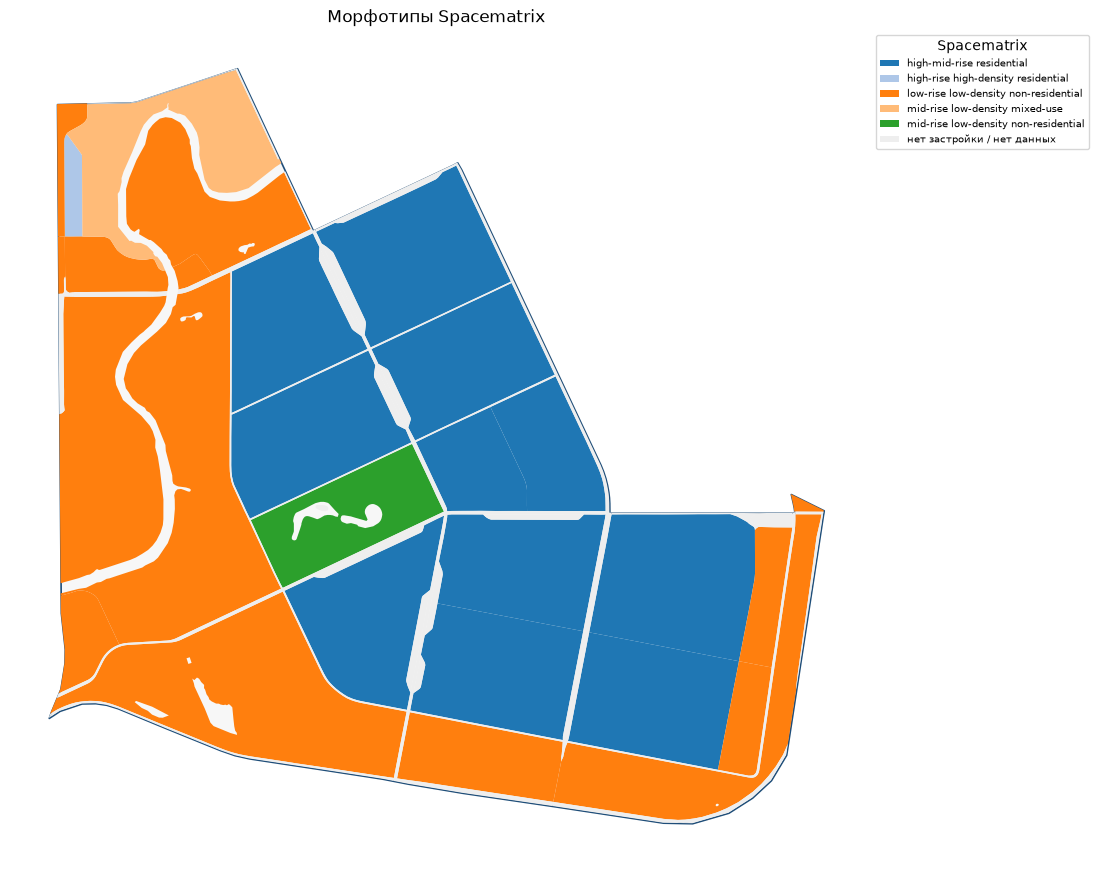

In [49]:
blocks_spacematrix = blocks.join(spacematrix_df[["cluster", "morphotype"]])
blocks_spacematrix_out = blocks_spacematrix.copy()
blocks_spacematrix_out.index = pd.Index(blocks.index, name="block_id")
save_geojson(blocks_spacematrix_out, PROCESSED_DIR / "blocks_spacematrix.geojson")

fig, ax = plt.subplots(figsize=(11, 11))
boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.2)
blocks_spacematrix.plot(
    column="morphotype",
    categorical=True,
    legend=True,
    ax=ax,
    cmap="tab20",
    missing_kwds={"color": "#eeeeee", "label": "нет застройки / нет данных"},
    legend_kwds={"loc": "upper left", "bbox_to_anchor": (1.01, 1), "fontsize": 7, "title": "Spacematrix"},
)
ax.set_title("Морфотипы Spacematrix")
ax.set_axis_off()
plt.show()

### 12.4. Морфотипы Strelka

Strelka использует те же `l`, `fsi`, `mxi`, но правила интерпретации другие.
Это альтернативная типология, полезная для сравнения с Spacematrix.
Кварталы без застройки также остаются без морфотипа.

In [50]:
if developed_count >= 1:
    strelka_df = get_strelka_morphotypes(density_df)
else:
    strelka_df = density_df.copy()
    strelka_df["morphotype"] = np.nan

strelka_df.index.name = "block_id"
print("Морфотипы Strelka:")
strelka_df["morphotype"].value_counts(dropna=False)

Морфотипы Strelka:


morphotype
NaN                               69
low-rise non-residential          15
mid-rise                           6
central model                      3
high-rise modern microdistrict     3
low-rise model                     1
Name: count, dtype: int64

💾 blocks_strelka.geojson: 97 объектов, 0.11 МБ


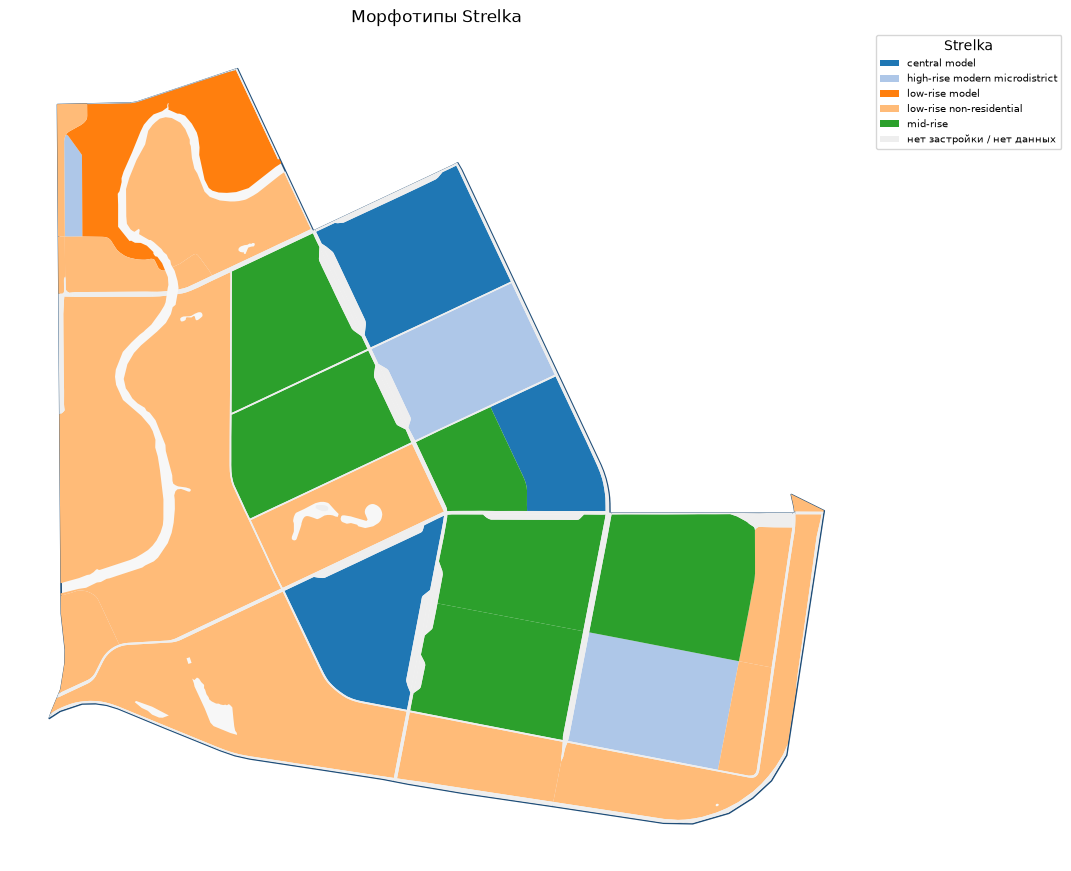

In [51]:
blocks_strelka = blocks.join(strelka_df[["morphotype"]])
blocks_strelka_out = blocks_strelka.copy()
blocks_strelka_out.index = pd.Index(blocks.index, name="block_id")
save_geojson(blocks_strelka_out, PROCESSED_DIR / "blocks_strelka.geojson")

fig, ax = plt.subplots(figsize=(11, 11))
boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.2)
blocks_strelka.plot(
    column="morphotype",
    categorical=True,
    legend=True,
    ax=ax,
    cmap="tab20",
    missing_kwds={"color": "#eeeeee", "label": "нет застройки / нет данных"},
    legend_kwds={"loc": "upper left", "bbox_to_anchor": (1.01, 1), "fontsize": 7, "title": "Strelka"},
)
ax.set_title("Морфотипы Strelka")
ax.set_axis_off()
plt.show()

### 12.5. Площадная доступность

`area_accessibility` — средневзвешенное время до всех кварталов территории,
где вес — площадь квартала. Показатель отвечает на вопрос:
«сколько в среднем занимает добраться из этого квартала в любую точку округа».

Чем меньше — тем лучше. Это **модельная оценка** по автомобильному графу.

Если в матрице есть недостижимые пары (`inf`), ноутбук:
1. считает показатель функцией BlocksNet;
2. проверяет результат на `inf`;
3. при необходимости пересчитывает среднее только по достижимым кварталам
   и явно предупреждает об этом.

In [52]:
area_acc_df = area_accessibility(acc_mx, buildings_blocks[["site_area"]])
area_acc_df.index.name = "block_id"

inf_after = int(np.isinf(area_acc_df["area_accessibility"]).sum())

if inf_after > 0:
    print(f"⚠️ Недостижимые пары дали inf в {inf_after} кварталах.")
    print("Пересчитываю среднее только по достижимым кварталам (с перенормировкой весов).")

    reachable_matrix = acc_mx.replace([np.inf, -np.inf], np.nan)
    weights = buildings_blocks["site_area"].reindex(acc_mx.columns).astype(float)
    weights = weights / weights.sum()
    weighted_sum = reachable_matrix.mul(weights, axis=1).sum(axis=1, skipna=True)
    weight_sum = reachable_matrix.notna().mul(weights, axis=1).sum(axis=1)
    area_acc_df["area_accessibility"] = weighted_sum / weight_sum
    area_acc_df.index.name = "block_id"
else:
    print("Недостижимых пар нет: результат совпадает с функцией BlocksNet.")

area_acc_df["area_accessibility"].describe()

Недостижимых пар нет: результат совпадает с функцией BlocksNet.


count    97.000000
mean      7.606325
std       1.323119
min       4.953265
25%       6.587140
50%       7.561531
75%       8.550448
max      11.365924
Name: area_accessibility, dtype: float64

💾 blocks_area_accessibility.geojson: 97 объектов, 0.11 МБ


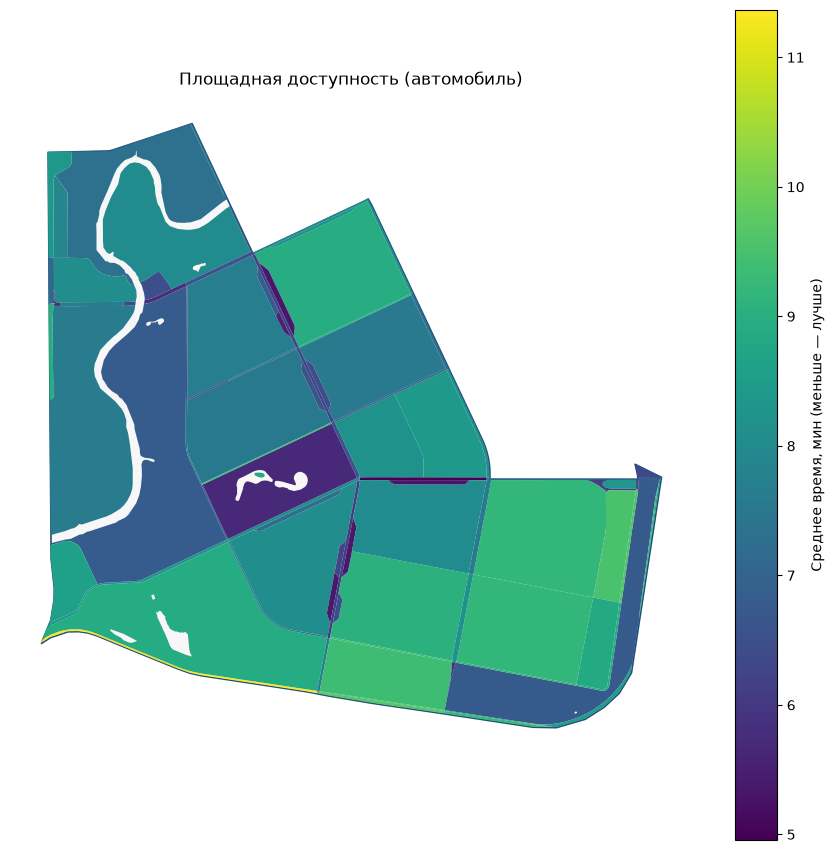

In [53]:
blocks_area_acc = blocks.join(area_acc_df)
blocks_area_acc_out = blocks_area_acc.copy()
blocks_area_acc_out.index = pd.Index(blocks.index, name="block_id")
save_geojson(blocks_area_acc_out, PROCESSED_DIR / "blocks_area_accessibility.geojson")

fig, ax = plt.subplots(figsize=(11, 11))
boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1.2)
blocks_area_acc.plot(
    column="area_accessibility",
    cmap="viridis",
    legend=True,
    ax=ax,
    missing_kwds={"color": "#eeeeee"},
    legend_kwds={"label": "Среднее время, мин (меньше — лучше)"},
)
ax.set_title("Площадная доступность (автомобиль)")
ax.set_axis_off()
plt.show()

## 13. Итоговый слой и сводка

Собираем все показатели в один GeoDataFrame `blocks_results`:
удобно для проверки, для дашборда и для экспорта в QGIS.
Матрица `N × N` **не** попадает в итоговый слой — она остаётся в CSV.

In [54]:
blocks_results = blocks.copy()

# Land use: сам класс, доля крупнейшей зоны и доли по классам
land_use_columns = [column for column in blocks_lu.columns if column != "geometry"]
blocks_results = blocks_results.join(blocks_lu[land_use_columns])

# Плотность и морфотипы
blocks_results = blocks_results.join(density_df[density_columns])
blocks_results = blocks_results.join(
    spacematrix_df[["cluster", "morphotype"]].rename(
        columns={"cluster": "spacematrix_cluster", "morphotype": "spacematrix_morphotype"}
    )
)
blocks_results = blocks_results.join(
    strelka_df[["morphotype"]].rename(columns={"morphotype": "strelka_morphotype"})
)

# Здания и школы
blocks_results = blocks_results.join(
    buildings_blocks[["population", "count"]].rename(columns={"count": "buildings_count"})
)
blocks_results = blocks_results.join(
    schools_blocks[["capacity"]].rename(columns={"capacity": "school_capacity"})
)

# Обеспеченность и площадная доступность
blocks_results = blocks_results.join(
    prov_df[
        [
            "demand",
            "demand_within",
            "demand_without",
            "capacity_within",
            "capacity_without",
            "provision_strong",
            "provision_weak",
        ]
    ]
)
blocks_results = blocks_results.join(area_acc_df)

# Понятные имена
blocks_results = blocks_results.rename(
    columns={
        "share": "land_use_share",
        **{land_use.value: f"lu_share_{land_use.value}" for land_use in LandUse},
    }
)
blocks_results["population_density_ha"] = blocks_results["population"] / (
    blocks_results["site_area"] / 10_000
)

blocks_results.index.name = "block_id"
blocks_results_out = blocks_results.copy()
blocks_results_out.index = pd.Index(blocks.index, name="block_id")
save_geojson(blocks_results_out, PROCESSED_DIR / "blocks_results.geojson")

print("Колонки итогового слоя:")
print(list(blocks_results.columns))

💾 blocks_results.geojson: 97 объектов, 0.19 МБ
Колонки итогового слоя:
['geometry', 'lu_share_residential', 'lu_share_business', 'lu_share_recreation', 'lu_share_industrial', 'lu_share_transport', 'lu_share_special', 'lu_share_agriculture', 'land_use', 'land_use_share', 'site_area', 'footprint_area', 'build_floor_area', 'living_area', 'fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living', 'spacematrix_cluster', 'spacematrix_morphotype', 'strelka_morphotype', 'population', 'buildings_count', 'school_capacity', 'demand', 'demand_within', 'demand_without', 'capacity_within', 'capacity_without', 'provision_strong', 'provision_weak', 'area_accessibility', 'population_density_ha']


In [55]:
total_population = float(blocks_results["population"].sum())
total_capacity = float(blocks_results["school_capacity"].sum())
total_demand = float(blocks_results["demand"].sum())
total_blocks = int(len(blocks_results))
built_share = float((blocks_results["fsi"] > 0).mean())
median_block_area = float(blocks.area.median())
population_density_km2 = total_population / area_km2

summary = {
    "territory": {
        "name": TERRITORY_NAME,
        "osm_relation": TERRITORY_OSM_ID,
        "area_km2": round(float(area_km2), 3),
        "work_crs": str(WORK_CRS),
    },
    "graph": {
        "source": GRAPH_URL,
        "member": GRAPH_MEMBER,
        "mode": "drive",
        "time_field": "time_min",
        "time_unit": "minutes",
        "time_source": GRAPH_TIME_SOURCE,
        "buffer_m": GRAPH_BUFFER_M,
        "nodes": int(graph.number_of_nodes()),
        "edges": int(graph.number_of_edges()),
    },
    "blocks": {
        "count": total_blocks,
        "median_area_m2": round(median_block_area, 1),
        "built_share": round(built_share, 4),
    },
    "population": {
        "total": round(total_population, 1),
        "density_per_km2": round(population_density_km2, 1),
        "type": "model estimate",
    },
    "schools": {
        "count": int(len(schools)),
        "capacity_total": round(total_capacity, 1),
        "capacity_type": "model estimate (250 places by default)",
        "demand_per_1000": school_demand_per_1000,
        "accessibility_min": school_accessibility_min,
        "demand_total": round(total_demand, 1),
        "provision_strong": round(strong_total, 4),
        "provision_weak": round(weak_total, 4),
    },
    "travel_time": {
        "median_min": round(median_time, 2),
        "p90_min": round(p90_time, 2),
        "max_min": round(max_time, 2),
        "share_unreachable": round(share_unreachable, 4),
    },
    "limitations": [
        "Accessibility is calculated by car, not on foot; school provision may be overstated.",
        "School capacity is imputed as 250 places per school.",
        "Population is modelled from living area, not taken from official statistics.",
        "Missing floor counts are imputed as 1 floor.",
        "Functional zones come from OSM landuse, not official zoning documents.",
    ],
}

summary_path = PROCESSED_DIR / "summary.json"
summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"💾 summary.json: {file_size_mb(summary_path):.2f} МБ")
summary

💾 summary.json: 0.00 МБ


{'territory': {'name': 'муниципальный округ Пороховые',
  'osm_relation': 'R1185384',
  'area_km2': 7.188,
  'work_crs': 'EPSG:32636'},
 'graph': {'source': 'https://github.com/IDUclub/blocksnet-data/releases/download/v0.0.1/saint_petersburg.zip',
  'member': 'graph_drive.pickle',
  'mode': 'drive',
  'time_field': 'time_min',
  'time_unit': 'minutes',
  'time_source': 'time_min (готовый граф BlocksNet Data)',
  'buffer_m': 1000,
  'nodes': 347,
  'edges': 658},
 'blocks': {'count': 97, 'median_area_m2': 7137.3, 'built_share': 0.2887},
 'population': {'total': 136053.0,
  'density_per_km2': np.float64(18928.0),
  'type': 'model estimate'},
 'schools': {'count': 19,
  'capacity_total': 4750.0,
  'capacity_type': 'model estimate (250 places by default)',
  'demand_per_1000': 120,
  'accessibility_min': 15,
  'demand_total': 16332.0,
  'provision_strong': 0.2908,
  'provision_weak': 0.2908},
 'travel_time': {'median_min': 6.96,
  'p90_min': 9.79,
  'max_min': 13.97,
  'share_unreachable':

In [56]:
summary_rows = pd.DataFrame(
    [
        ("Территория", round(area_km2, 2), "км²"),
        ("Кварталов", total_blocks, "шт."),
        ("Медианная площадь квартала", round(median_block_area, 0), "м²"),
        ("Доля застроенных кварталов", round(built_share, 3), "доля"),
        ("Население (модель)", round(total_population, 0), "чел."),
        ("Плотность населения (модель)", round(population_density_km2, 0), "чел./км²"),
        ("Школ", len(schools), "шт."),
        ("Вместимость школ (модель)", round(total_capacity, 0), "мест"),
        ("Расчётный спрос на школы", round(total_demand, 0), "мест"),
        ("Обеспеченность strong", round(strong_total, 3), "доля"),
        ("Обеспеченность weak", round(weak_total, 3), "доля"),
        ("Медианное время в пути", round(median_time, 1), "мин"),
        ("90-й процентиль времени", round(p90_time, 1), "мин"),
        ("Доля недостижимых пар", round(share_unreachable, 3), "доля"),
    ],
    columns=["Показатель", "Значение", "Единица"],
)
summary_rows.to_csv(PROCESSED_DIR / "summary.csv", index=False, encoding="utf-8-sig")
summary_rows

,Показатель,Значение,Единица
0,Территория,7.190,км²
1,Кварталов,97.000,шт.
2,Медианная площадь квартала,7137.000,м²
3,Доля застроенных кварталов,0.289,доля
4,Население (модель),136053.000,чел.
5,Плотность населения (модель),18928.000,чел./км²
6,Школ,19.000,шт.
7,Вместимость школ (модель),4750.000,мест
8,Расчётный спрос на школы,16332.000,мест
9,Обеспеченность strong,0.291,доля


In [57]:
key_columns = [
    "land_use",
    "site_area",
    "population",
    "population_density_ha",
    "school_capacity",
    "demand",
    "provision_strong",
    "provision_weak",
    "fsi",
    "gsi",
    "mxi",
    "l",
    "osr",
    "spacematrix_morphotype",
    "strelka_morphotype",
    "area_accessibility",
]

available_key_columns = [column for column in key_columns if column in blocks_results.columns]
missing_key_columns = [column for column in key_columns if column not in blocks_results.columns]
if missing_key_columns:
    print("⚠ Нет колонок:", missing_key_columns)

key_table = (
    blocks_results[available_key_columns]
    .sort_values("population", ascending=False)
    .head(15)
)
print("Ключевые показатели по кварталам (топ-15 по населению):")
key_table.round(3)

Ключевые показатели по кварталам (топ-15 по населению):


,land_use,site_area,population,population_density_ha,school_capacity,demand,provision_strong,provision_weak,fsi,gsi,mxi,l,osr,spacematrix_morphotype,strelka_morphotype,area_accessibility
block_id,,,,,,,,,,,,,,,,
16,residential,386102.873,15805.0,409.347,750.0,1897,0.395,0.395,1.495,0.181,0.822,8.266,0.548,high-mid-rise residential,mid-rise,9.169
43,residential,324978.152,15745.0,484.494,500.0,1890,0.265,0.265,1.709,0.171,0.851,10.012,0.485,high-mid-rise residential,high-rise modern microdistrict,9.178
0,residential,362971.408,15147.0,417.306,500.0,1818,0.275,0.275,1.513,0.172,0.828,8.804,0.548,high-mid-rise residential,central model,8.939
33,residential,294821.769,14233.0,482.766,500.0,1708,0.293,0.293,1.802,0.191,0.804,9.435,0.449,high-mid-rise residential,high-rise modern microdistrict,7.562
6,residential,312916.775,13971.0,446.477,250.0,1677,0.149,0.149,1.610,0.179,0.832,8.984,0.510,high-mid-rise residential,central model,8.085
28,residential,322389.542,13062.0,405.162,500.0,1568,0.319,0.319,1.463,0.173,0.831,8.478,0.565,high-mid-rise residential,mid-rise,9.041
2,residential,327241.837,10812.0,330.398,250.0,1298,0.193,0.193,1.199,0.152,0.828,7.900,0.707,high-mid-rise residential,mid-rise,7.544
49,residential,296419.150,9840.0,331.962,500.0,1181,0.423,0.423,1.416,0.204,0.704,6.945,0.562,high-mid-rise residential,mid-rise,8.027
40,residential,285770.038,9601.0,335.969,500.0,1153,0.434,0.434,1.288,0.168,0.783,7.673,0.646,high-mid-rise residential,mid-rise,7.680


In [58]:
column_dictionary = pd.DataFrame(
    [
        ("block_id", "Идентификатор квартала", "целое"),
        ("land_use", "Класс land use (OSM landuse → LandUse)", "категория"),
        ("land_use_share", "Доля крупнейшей функциональной зоны в квартале", "доля 0–1"),
        ("lu_share_*", "Доли площади по классам LandUse", "доля 0–1"),
        ("site_area", "Площадь квартала", "м²"),
        ("population", "Население квартала (модель)", "чел."),
        ("population_density_ha", "Плотность населения", "чел./га"),
        ("buildings_count", "Число зданий в квартале", "шт."),
        ("school_capacity", "Вместимость школ в квартале (модель)", "мест"),
        ("demand", "Расчётный спрос на школы", "мест"),
        ("demand_within", "Спрос, покрытый школами в пределах доступности", "мест"),
        ("demand_without", "Спрос, покрытый только школами дальше доступности", "мест"),
        ("capacity_within", "Вместимость школ в пределах доступности", "мест"),
        ("capacity_without", "Вместимость школ дальше доступности", "мест"),
        ("provision_strong", "Обеспеченность в пределах доступности", "доля 0–1"),
        ("provision_weak", "Обеспеченность с учётом внешних связей", "доля 0–1"),
        ("fsi", "Floor Space Index", "безразмерный"),
        ("gsi", "Ground Space Index", "доля 0–1"),
        ("mxi", "Доля жилой площади", "доля 0–1"),
        ("l", "Средняя этажность", "этажи"),
        ("osr", "Open Space Ratio", "безразмерный"),
        ("share_living", "Доля жилой площади", "доля"),
        ("share_non_living", "Доля нежилой площади", "доля"),
        ("spacematrix_cluster", "Номер кластера Spacematrix", "целое"),
        ("spacematrix_morphotype", "Морфотип Spacematrix", "категория"),
        ("strelka_morphotype", "Морфотип Strelka", "категория"),
        ("area_accessibility", "Средневзвешенное время до кварталов", "минуты"),
    ],
    columns=["Колонка", "Смысл", "Единица"],
)
column_dictionary

,Колонка,Смысл,Единица
0,block_id,Идентификатор квартала,целое
1,land_use,Класс land use (OSM landuse → LandUse),категория
2,land_use_share,Доля крупнейшей функциональной зоны в квартале,доля 0–1
3,lu_share_*,Доли площади по классам LandUse,доля 0–1
4,site_area,Площадь квартала,м²
5,population,Население квартала (модель),чел.
6,population_density_ha,Плотность населения,чел./га
7,buildings_count,Число зданий в квартале,шт.
8,school_capacity,Вместимость школ в квартале (модель),мест
9,demand,Расчётный спрос на школы,мест


## 14. Проверка результатов

Автоматический чек-лист. `[OK]` — проверка пройдена, `[!]` — нужно посмотреть внимательнее.
Это не «истина», а способ заметить технические проблемы до выводов.

In [59]:
checks = []


def check(title, condition, detail=""):
    checks.append({"Проверка": title, "Результат": "OK" if condition else "!", "Детали": detail})
    print(("[OK] " if condition else "[!]  ") + title + (f" — {detail}" if detail else ""))


diagonal = np.diag(acc_mx.to_numpy(dtype="float64"))
check("Кварталы нарезаны", len(blocks) > 0, f"{len(blocks)} шт.")
check("block_id уникальны", blocks.index.is_unique, f"{blocks.index.nunique()} значений")
check("Все геометрии валидны", bool(blocks.geometry.is_valid.all()), "проверка shapely")
check("Матрица квадратная и совпадает с кварталами",
      acc_mx.shape == (len(blocks), len(blocks)), f"{acc_mx.shape}")
check("Индексы матрицы совпадают с block_id",
      set(acc_mx.index) == set(blocks.index), "множества индексов")
check("Диагональ матрицы равна 0",
      bool(np.allclose(diagonal, 0, atol=1e-3)), f"max = {float(diagonal.max()):.4f}")
check("Население больше нуля", total_population > 0, f"{total_population:,.0f} чел.")
check("Вместимость школ больше нуля", total_capacity > 0, f"{total_capacity:,.0f} мест")
check("Доля недостижимых пар меньше 10%", share_unreachable < 0.1, f"{share_unreachable:.1%}")
no_land_use_area_share = float(
    blocks_results.loc[blocks_results["land_use"].isna()].area.sum()
    / blocks_results.area.sum()
)
check(
    "Площадь без land use меньше 10%",
    no_land_use_area_share < 0.10,
    f"{int(blocks_results['land_use'].isna().sum())} кварталов, "
    f"{no_land_use_area_share:.1%} площади",
)
check("Нет отрицательной жилой площади",
      bool((blocks_results["living_area"] >= 0).all()), "минимум ≥ 0")
check("Обеспеченность посчитана", prov_df["provision_strong"].notna().any(), "есть значения")

checks_df = pd.DataFrame(checks)
checks_df

[OK] Кварталы нарезаны — 97 шт.
[OK] block_id уникальны — 97 значений
[OK] Все геометрии валидны — проверка shapely
[OK] Матрица квадратная и совпадает с кварталами — (97, 97)
[OK] Индексы матрицы совпадают с block_id — множества индексов
[OK] Диагональ матрицы равна 0 — max = 0.0000
[OK] Население больше нуля — 136,053 чел.
[OK] Вместимость школ больше нуля — 4,750 мест
[OK] Доля недостижимых пар меньше 10% — 0.0%
[OK] Площадь без land use меньше 10% — 51 кварталов, 4.3% площади
[OK] Нет отрицательной жилой площади — минимум ≥ 0
[OK] Обеспеченность посчитана — есть значения


,Проверка,Результат,Детали
0,Кварталы нарезаны,OK,97 шт.
1,block_id уникальны,OK,97 значений
2,Все геометрии валидны,OK,проверка shapely
3,Матрица квадратная и совпадает с кварталами,OK,"(97, 97)"
4,Индексы матрицы совпадают с block_id,OK,множества индексов
5,Диагональ матрицы равна 0,OK,max = 0.0000
6,Население больше нуля,OK,"136,053 чел."
7,Вместимость школ больше нуля,OK,"4,750 мест"
8,Доля недостижимых пар меньше 10%,OK,0.0%
9,Площадь без land use меньше 10%,OK,"51 кварталов, 4.3% площади"


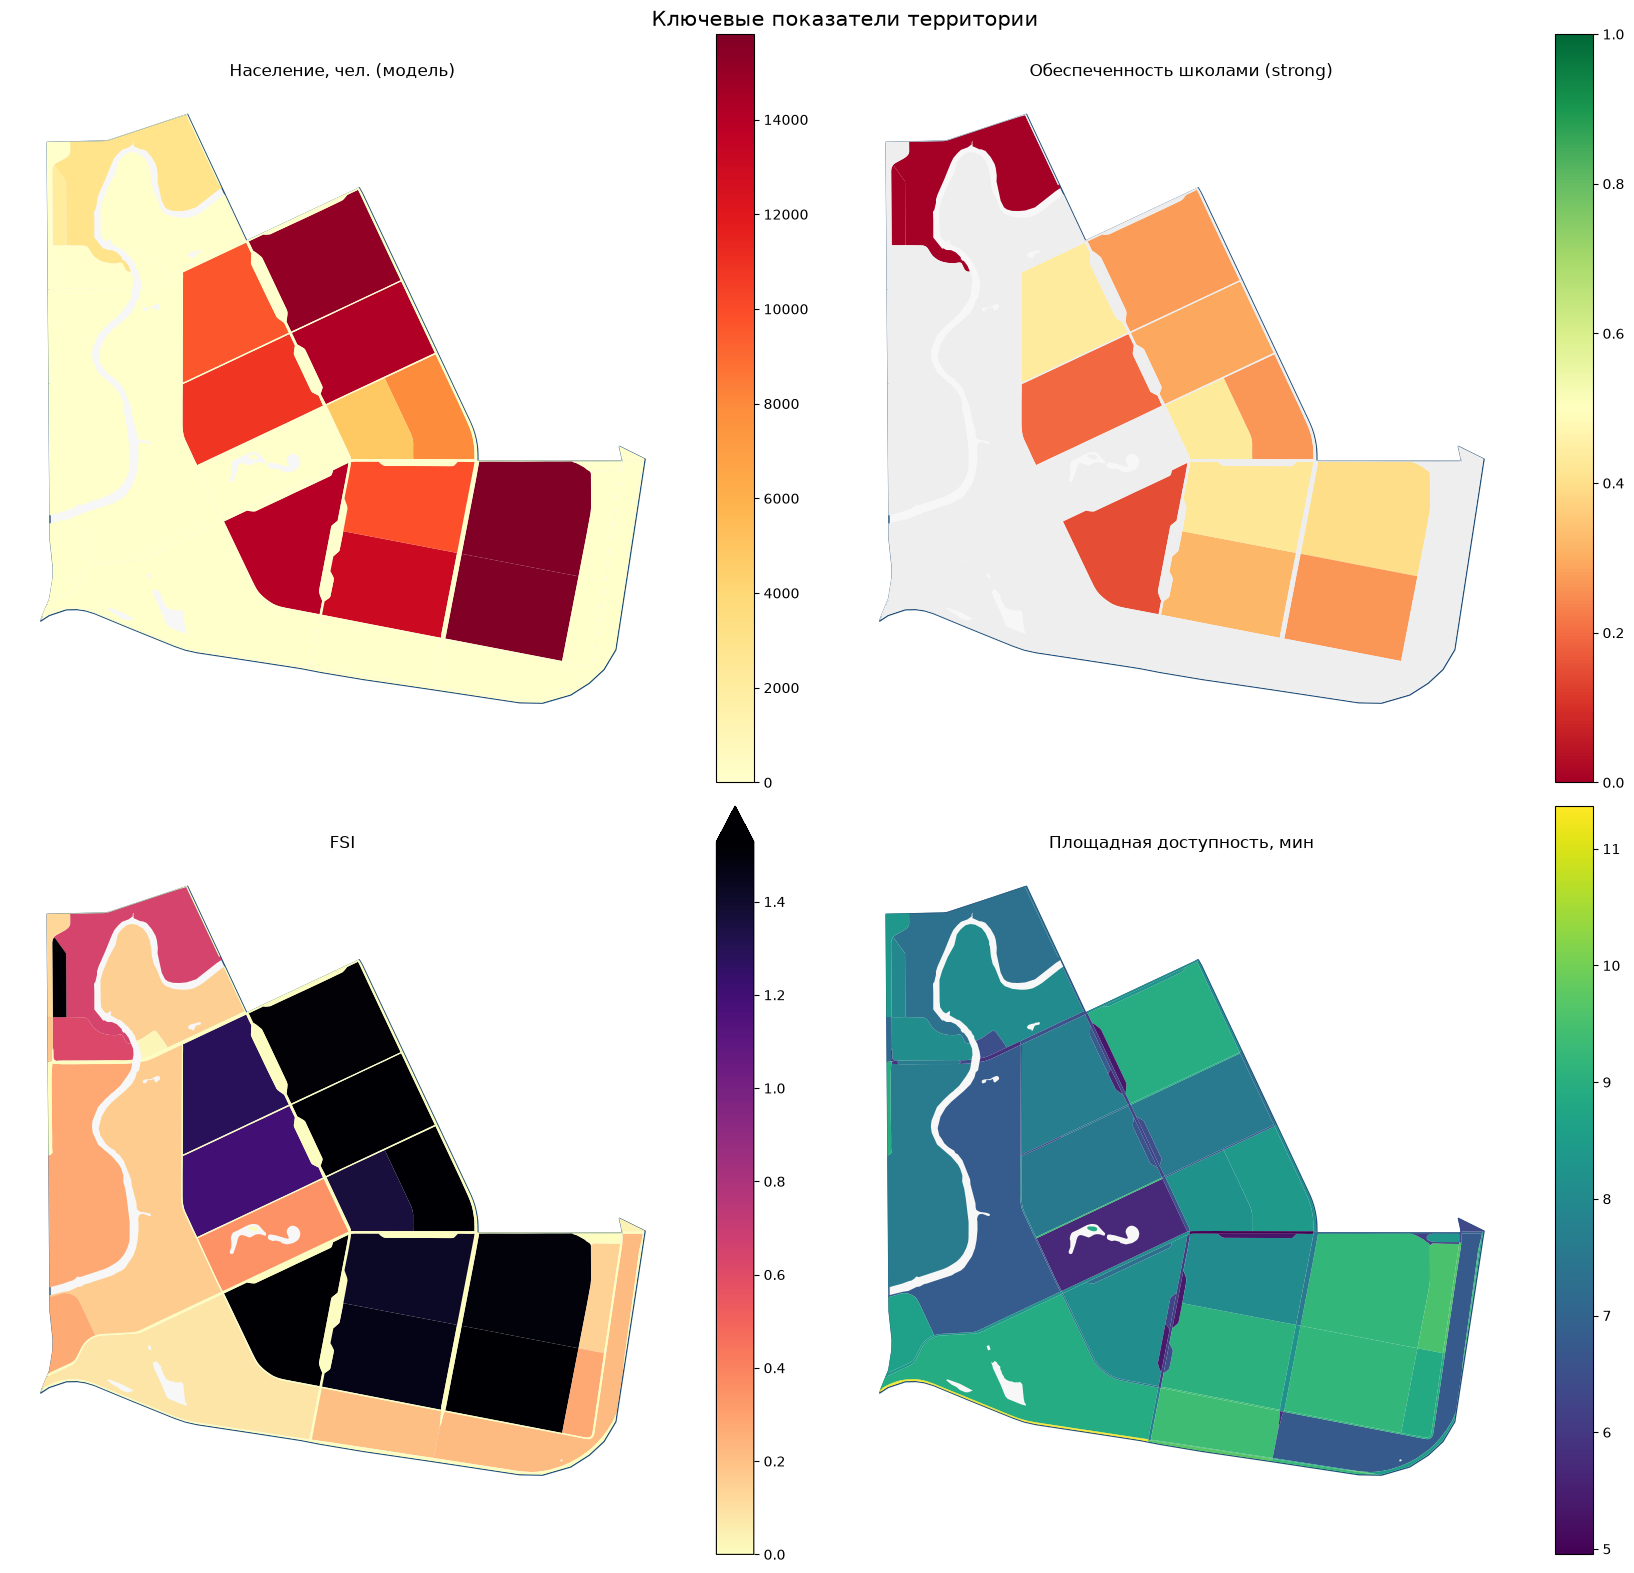

In [60]:
fig, axes = plt.subplots(2, 2, figsize=(17, 16))
fsi_cap = float(np.nanpercentile(blocks_results["fsi"], 95))

panels = [
    ("population", "Население, чел. (модель)", "YlOrRd", None, None),
    ("provision_strong", "Обеспеченность школами (strong)", "RdYlGn", 0, 1),
    ("fsi", "FSI", "magma_r", None, max(fsi_cap, 0.1)),
    ("area_accessibility", "Площадная доступность, мин", "viridis", None, None),
]

for ax, (column, title, cmap, vmin, vmax) in zip(axes.ravel(), panels):
    boundary.plot(ax=ax, facecolor="#f7f7f7", edgecolor="#1f4e79", linewidth=1)
    blocks_results.plot(
        column=column,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        legend=True,
        ax=ax,
        missing_kwds={"color": "#eeeeee"},
    )
    ax.set_title(title)
    ax.set_axis_off()

plt.suptitle("Ключевые показатели территории", fontsize=15)
plt.tight_layout()
plt.show()

## 15. Краткие выводы о территории

Ниже — **автоматические цифры** из расчёта. Их нужно читать вместе с ограничениями:
это модельная оценка, а не официальная статистика.

После первого запуска этот раздел можно дополнить содержательными выводами:
где концентрируется население, какие морфотипы преобладают, какие кварталы
формально обеспечены школами, а какие — только за счёт автомобильной доступности.

In [61]:
land_use_top = (
    blocks_results.assign(area_m2=blocks_results.area)
    .groupby("land_use", dropna=False)["area_m2"]
    .sum()
    .sort_values(ascending=False)
)
land_use_top_share = land_use_top / land_use_top.sum()

print("КРАТКИЕ ВЫВОДЫ (автоматические цифры)")
print("=" * 60)
print(f"Площадь округа: {area_km2:.2f} км²")
print(f"Кварталов: {total_blocks}; медианная площадь: {median_block_area:,.0f} м²")
print(f"Доля застроенных кварталов (FSI > 0): {built_share:.1%}")
print()
print(f"Население (модель): {total_population:,.0f} чел.")
print(f"Плотность населения (модель): {population_density_km2:,.0f} чел./км²")
print()
print(f"Школ: {len(schools)}; вместимость (модель): {total_capacity:,.0f} мест")
print(f"Расчётный спрос: {total_demand:,.0f} мест при нормативе {school_demand_per_1000} мест/1000 жителей")
print(f"Обеспеченность: strong {strong_total:.1%}, weak {weak_total:.1%}")
print()
print(f"Медианное время между кварталами (авто): {median_time:.1f} мин")
print(f"90-й процентиль: {p90_time:.1f} мин; доля недостижимых пар: {share_unreachable:.1%}")
print(f"Медианная площадная доступность: {float(blocks_results['area_accessibility'].median()):.1f} мин")
print()
print("Структура площади по land use (топ-5):")
for name, share in land_use_top_share.head(5).items():
    label = "нет land use" if name is None else name
    print(f"  • {label}: {share:.1%}")

if strong_total >= 0.9:
    verdict = "формально очень высокая"
elif strong_total >= 0.7:
    verdict = "формально высокая"
elif strong_total >= 0.5:
    verdict = "средняя"
else:
    verdict = "низкая"

print()
print(f"Формальная обеспеченность школами: {verdict} ({strong_total:.0%}).")
print("НО: это доступность на автомобиле. Школьники обычно ходят пешком,")
print("поэтому реальная пешеходная обеспеченность может быть заметно ниже.")

КРАТКИЕ ВЫВОДЫ (автоматические цифры)
Площадь округа: 7.19 км²
Кварталов: 97; медианная площадь: 7,137 м²
Доля застроенных кварталов (FSI > 0): 28.9%

Население (модель): 136,053 чел.
Плотность населения (модель): 18,928 чел./км²

Школ: 19; вместимость (модель): 4,750 мест
Расчётный спрос: 16,332 мест при нормативе 120 мест/1000 жителей
Обеспеченность: strong 29.1%, weak 29.1%

Медианное время между кварталами (авто): 7.0 мин
90-й процентиль: 9.8 мин; доля недостижимых пар: 0.0%
Медианная площадная доступность: 7.6 мин

Структура площади по land use (топ-5):
  • residential: 46.8%
  • industrial: 28.4%
  • recreation: 12.8%
  • business: 6.7%
  • nan: 4.3%

Формальная обеспеченность школами: низкая (29%).
НО: это доступность на автомобиле. Школьники обычно ходят пешком,
поэтому реальная пешеходная обеспеченность может быть заметно ниже.


### Как читать эти цифры

* **Население и плотность** — модельные. Они выведены из жилой площади зданий,
  а не из официальной статистики. Модель даёт 136 053 чел., официальные данные округа —
  около 115–120 тыс. чел., то есть модель выше на 13–18 %. При пропущенной этажности
  население занижается.
* **Обеспеченность школами** — формальная оценка по автомобильной доступности.
  Она отвечает на вопрос «сколько детей может добраться до школы за 15 минут на машине»,
  а не «сколько детей ходит в школу пешком». Кроме того, в OSM нет вместимости школ:
  всем 19 школам поставлено 250 мест, а реальные школы рассчитаны на 600–1200.
  Поэтому 29 % — нижняя граница, а не факт.
* **Граф пришлось исправить.** После обрезки он сохранял номера узлов всего Петербурга,
  а IduEdu использует номера как индексы. Добавлены крупнейшая сильно связная компонента
  и перенумерация 0…N−1; без этого матрица не считалась.
* **Морфотипы** — результат кластеризации. Названия кластеров условны и зависят
  от набора кварталов; их нельзя сравнивать с типологией другого города напрямую.
* **Площадная доступность** — среднее время до всех кварталов округа.
  Она чувствительна к границам территории: за пределами округа доступность не учитывается.
* **Land use** — OSM `landuse`, а не официальные ПЗЗ. Часть кварталов останется без класса.
* **Автобусный парк справа** на карте выглядит как `industrial`: в OSM он размечен
  `landuse=industrial`, поэтому правило `depot → transport` не сработало. Мы оставили
  так — на население и школы это не влияет, но в выводах об этом стоит сказать.

### Что проверить глазами на картах

1. Совпадают ли границы округа с ожидаемыми.
2. Нет ли «дыр» и кварталов-пылинок.
3. Не выглядят ли зоны высокой обеспеченности подозрительно: часто это кварталы
   без жителей или без спроса.
4. Где население концентрируется, а где его почти нет.
5. Совпадают ли морфотипы с визуальной картиной застройки.

## 16. Ограничения исследования

Эти ограничения нужно перенести в дашборд и в текстовый вывод.

1. **Автомобильный граф вместо пешеходного.**
   Школьники обычно ходят пешком. 15 минут на машине покрывают почти весь округ,
   поэтому обеспеченность школами может быть **завышена**. Это главное ограничение.
2. **Вместимость школ — модель, и она занижена.** В OSM нет числа мест, поэтому всем
   19 школам поставлено минимальное значение 250 мест. Реальные школы Петербурга
   обычно рассчитаны на 600–1200 учеников: при 600 местах это 11 400 мест,
   при 1200 — 22 800. Это дало бы ориентировочно 70–100 % спроса вместо 29 %.
   Суммарная вместимость и обеспеченность — оценки, а не факт.
3. **Население — модель, и оно завышено.** Жилая площадь восстанавливается из площади
   этажей, население — из жилой площади по норме 30 м²/чел. Модель даёт 136 053 чел.,
   официальные данные округа — около 115–120 тыс. чел. (завышение на 13–18 %).
   Официальная статистика в расчёте не используется.
4. **Этажность — частично модель.** Пропуски заполняются 1 этажом.
5. **Функциональные зоны — OSM `landuse`,** а не официальные ПЗЗ.
6. **Граф без пробок и без общественного транспорта.** Это не прогноз транспортной доступности.
7. **Правки land use — отклонения от `pipeline.ipynb`.** Парки, парковки,
   `railway`/`depot` → transport, фильтр газонов и объединение «пылинок» < 500 м²
   сделаны по локальной проверке территории и влияют на карту land use.
8. **Границы территории.** Всё, что за границей округа, в площадной доступности не учитывается,
   хотя жители реально пользуются соседними районами.
9. **Данные OSM могут быть неполными.** Школы, здания и дороги могли измениться
   после даты выгрузки; часть объектов может отсутствовать.
10. **Автобусный парк справа остался `industrial`.** В OSM он размечен как
    `landuse=industrial`, а не `depot`, поэтому правило `depot → transport` на него
    не сработало. Мы сознательно оставили класс как есть: на население и школы это
    не влияет, но на карте land use территория выглядит промышленной, хотя по факту
    это транспортная площадка.
11. **Перераспределения мест между кварталами нет.** BlocksNet сначала покрывает спрос
    собственными местами квартала. При общем дефиците вся вместимость расходуется «на себя»,
    поэтому `provision_links.csv` пуст, а карта обеспеченности показывает отношение
    «свои места / свой спрос», а не 15-минутную доступность.
12. **Матрица времени падала без исправления графа.** IduEdu использует номера узлов как
    индексы массива, а после обрезки граф сохранял номера всего Петербурга. В ячейке 8.2
    добавлены выделение крупнейшей сильно связной компоненты и перенумерация узлов 0…N−1.
    После исправления: 347 узлов, 658 рёбер, недостижимых пар нет.
13. **`provision_weak` совпадает с `provision_strong`.** При `max_depth = 1` BlocksNet
    учитывает только связи в пределах 15 минут, поэтому «слабая» обеспеченность
    не отличается от «сильной». Это поведение библиотеки, а не ошибка расчёта.

**Вывод:** ноутбук даёт воспроизводимую учебную оценку и позволяет сравнить кварталы
между собой. Он не заменяет официальную статистику, натурные обследования
и нормативный расчёт доступности школ.

## 17. Повторный запуск в VS Code

### Первый запуск (один раз)

В PowerShell:

```powershell
cd "C:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate"
.\.venv\Scripts\Activate.ps1
python -m pip install -e ".[dev,research]"
code .
```

Если PowerShell не разрешает активацию окружения:

```powershell
cd "C:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate"
.\.venv\Scripts\python.exe -m pip install -e ".[dev,research]"
code .
```

В VS Code:

1. Установите расширения **Python** и **Jupyter** от Microsoft.
2. `Ctrl+Shift+P` → **Python: Select Interpreter** → `.venv\Scripts\python.exe`.
3. Откройте `examples\porokhovye_research.ipynb`.
4. Справа вверху **Select Kernel** → **Python Environments** → `.venv`.
5. Запускайте ячейки кнопкой ▶ или `Shift+Enter`.

### Обычный повторный запуск

1. Откройте ноутбук.
2. Убедитесь, что ядро `.venv`.
3. `Ctrl+Shift+P` → **Notebook: Restart Kernel**.
4. Запускайте сверху вниз. Готовые файлы будут прочитаны с диска.

### Если нужно пересчитать заново

| Что сделать | Как |
|---|---|
| Заново скачать данные OSM | В ячейке с путями поставьте `FORCE_REDOWNLOAD = True` |
| Заново скачать граф | `FORCE_REDOWNLOAD = True` |
| Заново посчитать матрицу времени | `FORCE_RECALCULATE = True` |
| Заново нарезать кварталы | В ячейке 7.1 поставьте `FORCE_REBUILD_BLOCKS = True` |
| Пересчитать объединение и land use | Запустите раздел 7 сверху вниз: нарезка берётся из `blocks_cut.geojson`, объединение считается заново |
| Изменить порог объединения | Переменная `MIN_BLOCK_AREA_M2` в ячейке 7.1.1 |
| Полностью очистить кэш | Удалите папку `examples/data/porokhovye/` и запустите ноутбук заново |

> После `FORCE_REDOWNLOAD = True` не забудьте вернуть `False`, иначе данные будут
> скачиваться при каждом запуске.

### Если что-то пошло не так

| Симптом | Что проверить |
|---|---|
| `ModuleNotFoundError: blocksnet` | Выбрано не то ядро. Select Kernel → `.venv` |
| Overpass API не отвечает | Подождите 1–2 минуты и запустите ячейку снова; уже скачанные слои сохранятся |
| `502 Bad Gateway` от Overpass | В ячейке с настройками уже стоит зеркало `maps.mail.ru`; если и оно недоступно — верните `overpass-api.de` |
| Парки или парковки не скачались | Ячейка 7.2.1 напечатает предупреждение и продолжит без этого слоя |
| Не скачался граф | Скачайте `saint_petersburg.zip` вручную, извлеките `graph_drive.pickle` в `raw/` |
| Матрица считается очень долго | Это нормально для первого запуска; не прерывайте |
| Пустые карты | Проверьте, что слои в `WORK_CRS`, и что `block_id` не потерялся |

### Что изменилось после проверки территории

Повторный запуск раздела 7 дополнительно:

* скачает `raw/parks_green.geojson` и `raw/parkings.geojson`;
* объединит «пылинки» меньше 500 м²;
* назначит `transport` для `landuse=railway` и `landuse=depot`;
* отбросит узкие и мелкие газоны.

Числа кварталов и land use поэтому будут отличаться от первого запуска — это ожидаемо.

### Куда смотреть результаты

* `examples/data/porokhovye/processed/blocks_results.geojson` — все показатели по кварталам.
* `examples/data/porokhovye/processed/summary.json` — ключевые цифры для отчёта.
* `examples/data/porokhovye/processed/accessibility_matrix.csv` — матрица времени.
* `examples/data/porokhovye/processed/provision_links.csv` — связи «квартал спроса → школа».

## 18. Что дальше: интерактивный дашборд (< 20 МБ)

После ноутбука отдельным этапом собирается **один HTML-файл** `examples/dashboard.html`.
Он открывается в браузере без сервера и не требует Jupyter.

### Скрипт сборки

`examples/build_porokhovye_dashboard.py` — отдельный Python-файл. Он:

* **читает только готовые файлы** и ничего не скачивает;
* **не пересчитывает показатели** — только суммы, доли и гистограммы для графиков;
* собирает карту, графики, таблицы, выводы и ограничения в один HTML;
* проверяет размер и при необходимости сильнее упрощает геометрию.

### Что войдёт в дашборд

* KPI-карточки: площадь, кварталы, население, плотность, школы, вместимость, спрос,
  обеспеченность, медианное время;
* интерактивная карта (folium): land use, население, обеспеченность, FSI, GSI,
  площадная доступность, морфотипы Spacematrix и Strelka, школы, граница округа,
  уличная сеть графа. Слои включаются по одному в правом верхнем углу;
* карточка квартала при наведении: land use, население, школы, спрос, обеспеченность,
  FSI/GSI, морфотип, доступность;
* графики Chart.js: структура land use, население, обеспеченность, вместимость и спрос,
  гистограмма FSI, время в пути, площадная доступность, морфотипы;
* таблицы: паспорт территории, топ-15 кварталов, все 97 кварталов с фильтром, школы
  и раскрывающийся словарь всех 37 полей GeoJSON;
* выводы, проверка территории, ограничения, источники и команда повторной сборки.

### Бюджет размера

Лимит — **20 МБ**, ожидаемый размер — **1–3 МБ**. Поэтому:

1. Геометрия упрощается в метрической СК (допуск 3 м, при необходимости 8 или 20 м)
   и округляется до 6 знаков (~0,1 м).
2. Полная матрица `N × N` **не встраивается**: только статистика и гистограмма.
3. Сырые здания (0,5 МБ) и весь граф **не встраиваются**; из графа — только уличная сеть.
4. Графики — Chart.js с CDN; карта — тайлы CartoDB. Браузеру нужен интернет,
   сам скрипт работает офлайн.
5. Скрипт проверяет размер и при превышении 20 МБ усиливает упрощение.

> Раньше в плане было «одна геометрия встраивается один раз». На практике используется
> несколько тематических слоёв folium: так переключение показателя работает без
> самописного JavaScript. Геометрия при этом упрощается, поэтому файл всё равно
> остаётся в пределах нескольких мегабайт.

### Какие файлы читает скрипт

* `processed/blocks_results.geojson` — все показатели по кварталам;
* `processed/summary.json` — ключевые цифры;
* `processed/accessibility_matrix.csv` — гистограмма времени;
* `processed/blocks_schools.geojson` — школы по кварталам;
* `processed/graph_edges.geojson` — уличная сеть графа;
* `raw/school.geojson`, `raw/boundary.geojson` — школы и граница;
* `processed/provision_links.csv` — читается, но пуст: см. раздел 12.1.

### Запуск

В PowerShell из корня проекта:

```powershell
cd "C:\Users\azzuh\OneDrive\Dokumen\1. ITMO\ИИ\python-package-boilerplate"
.\.venv\Scripts\python.exe examples\build_porokhovye_dashboard.py
```

Результат: `examples\dashboard.html`. Откройте его двойным щелчком.


## 19. Чек-лист после первого запуска

- [ ] Версия BlocksNet — `1.0.0a9`, ядро `.venv`.
- [ ] Граница загрузилась именно как округ Пороховые, площадь правдоподобна.
- [ ] Кварталы нарезаны, число и площади выглядят разумно.
- [ ] Нет массовых пустых или невалидных геометрий.
- [ ] «Пылинки» меньше 500 м² объединены, в таблице качества это видно.
- [ ] Парки (`leisure=park/garden`) и парковки попали в слой зон.
- [ ] У `landuse=railway` и `landuse=depot` класс `transport`.
- [ ] Узкие газоны вдоль дорог не перекрывают назначение квартала.
- [ ] Land use назначен, список зон без правил просмотрен.
- [ ] Матрица времени квадратная, диагональ нулевая, время в минутах.
- [ ] Население и вместимость школ больше нуля.
- [ ] Обеспеченность и морфотипы посчитаны, на картах нет сплошных пропусков.
- [ ] Повторный запуск использует кэш и даёт те же цифры.
- [ ] Ограничение про автомобиль и пешеходную доступность школ выписано в выводы.
- [ ] `blocks_results.geojson` и `summary.json` сохранены.
- [ ] `examples/build_porokhovye_dashboard.py` запускается без ошибок.
- [ ] `examples/dashboard.html` открывается двойным щелчком и весит меньше 20 МБ.
- [ ] На карте включаются слои, при наведении видна карточка квартала.
- [ ] В дашборде видны предупреждения про 29 %, население и автомобильный граф.

**После остановки** напишите, какие метрики и услуги включаем в расчёт.
**После полного запуска** можно переходить к сборке дашборда.